# EN3150 A03 - Final RealWaste notebook

The saved outputs contain the recorded results. Run the cells with `RUN_TRAINING=False` to view them. Set it to `True` to train all four models from scratch using the same RealWaste split. Use a fresh `OUTPUT_DIR` for each run. The two custom networks use 30 epochs; the pretrained models train the classifier head with a frozen backbone, then fine-tune the backbone. The optimizer study is optional.

The digits notebook is a separate dataset experiment and is excluded from this comparison.

In [1]:
import copy
import datetime
import hashlib
import json
import os
import random
import time
import urllib.error
import urllib.request
import zipfile
from concurrent.futures import ThreadPoolExecutor
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.optim as optim
from IPython.display import Image as DisplayImage, display
from PIL import Image
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix, f1_score, precision_score, recall_score
from sklearn.model_selection import train_test_split
from torch.utils.data import DataLoader, Dataset, Subset, TensorDataset
from torchvision import datasets, models, transforms


In [2]:
RUN_TRAINING = False
RUN_OPTIMIZER_COMPARISON = False
MOUNT_GOOGLE_DRIVE = False
DATA_DIR = ""
DOWNLOAD_DATASET = True
IMAGE_SIZE = 64
SPLIT_SEED = 42
OUTPUT_DIR = Path("results/final_reproduction")
ROOT = Path.cwd()
RECORDED_DIR = Path('results/final')
REPOSITORY_RAW_BASES = ("https://raw.githubusercontent.com/AyubUmair/Pattern-Recognition/hakam/assignment-improvements/", "https://raw.githubusercontent.com/AyubUmair/Pattern-Recognition/main/")
TRAINING_SETTINGS = {'custom_models': ['Model A', 'Model B'],
 'sota_models': ['MobileNetV2', 'EfficientNet-B0'],
 'custom_epochs': 30,
 'head_epochs': 5,
 'fine_tune_epochs': 20,
 'batch_size': 32,
 'custom_lr': 0.001,
 'head_lr': 0.001,
 'fine_tune_lr': 1e-05,
 'weight_decay': 0.0001,
 'label_smoothing': 0,
 'lr_patience': 3,
 'early_stopping_patience': 7,
 'num_workers': 0,
 'seed': 42,
 'pretrained': True}
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", device)


Device: cpu


## Models

All inputs are RGB at 64 by 64 pixels. Model A interleaves standard convolutions and max-pooling. Model B uses depthwise separable blocks and global average pooling. It has 9,033 trainable parameters, below the 100,000 limit. Hidden custom-model activations use ReLU; classifiers return logits.

In [3]:
class Standard_Model(nn.Module):
  def __init__(self,num_of_classes):
    super(Standard_Model,self).__init__()
    self.features = nn.Sequential(
        nn.Conv2d(3, 16, kernel_size = 3, padding = 1),
        nn.ReLU(inplace = True),
        nn.MaxPool2d(kernel_size = 2, stride = 2),
        nn.Conv2d(16, 32,kernel_size = 3, padding = 1),
        nn.ReLU(inplace = True),
        nn.MaxPool2d(kernel_size = 2, stride = 2),
        nn.Conv2d(32, 64, kernel_size = 3, padding = 1),
        nn.ReLU(inplace = True),
        nn.MaxPool2d(kernel_size = 2, stride = 2)

    )

    self.classifier = nn.Sequential(
        nn.Flatten(),
        nn.Linear(64*8*8, 128),
        nn.ReLU(inplace = True),
        nn.Linear(128, num_of_classes)
    )

  def forward(self,x):
    x = self.features(x)
    x = self.classifier(x)
    return x


class DepthWiseSeperableConvolution(nn.Module):
  def __init__(self, in_channels, out_channels, stride = 1):
    super(DepthWiseSeperableConvolution, self).__init__()
    self.depthwise = nn.Conv2d(
        in_channels,
        in_channels,
        kernel_size = 3,
        stride = stride,
        padding = 1,
        groups = in_channels,
        bias = False
    )
    self.pointwise = nn.Conv2d(
        in_channels,
        out_channels,
        kernel_size = 1,
        bias = False
    )
    self.bn = nn.BatchNorm2d(out_channels)
    self.relu = nn.ReLU(inplace = True)

  def forward(self,x):
    x = self.depthwise(x)
    x = self.pointwise(x)
    x = self.bn(x)
    return self.relu(x)

class LightWeightModel(nn.Module):
  def __init__(self, num_classes):
        super(LightWeightModel, self).__init__()
        self.features = nn.Sequential(
            nn.Conv2d(3, 16, kernel_size=3, padding=1, stride=2, bias=False),
            nn.BatchNorm2d(16),
            nn.ReLU(inplace=True),
            DepthWiseSeperableConvolution(16, 32, stride=2),
            DepthWiseSeperableConvolution(32, 64, stride=2),
            DepthWiseSeperableConvolution(64, 64, stride=1),
            nn.AdaptiveAvgPool2d((1, 1))
        )
        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Linear(64, num_classes)
        )

  def forward(self, x):
      x = self.features(x)
      x = self.classifier(x)
      return x


def count_parameters(model):
    return sum(p.numel() for p in model.parameters() if p.requires_grad)
def get_model_size_mb(model):
    param_size = 0
    for param in model.parameters():
        param_size += param.nelement() * param.element_size()
    buffer_size = 0
    for buffer in model.buffers():
        buffer_size += buffer.nelement() * buffer.element_size()
    size_all_mb = (param_size + buffer_size) / 1024**2
    return size_all_mb


## Data and training helpers

The split is stratified 70/15/15 with seed 42. Resize and ImageNet normalization are deterministic; the final configuration uses no random augmentation. Preprocessed image tensors are cached in RAM. Custom models use Adam at 0.001 with plain cross-entropy and no scheduler. Transfer learning freezes the feature extractor first, then fine-tunes at a lower learning rate with batch-normalization statistics and parameters frozen. Checkpoints are selected using validation accuracy.

In [4]:
def seed_experiment(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False

def state_fingerprint(state):
    digest = hashlib.sha256()
    for name, value in sorted(state.items()):
        digest.update(name.encode("utf-8"))
        digest.update(value.detach().cpu().contiguous().numpy().tobytes())
    return digest.hexdigest()

class RecordedRandomSampler(torch.utils.data.Sampler):
    def __init__(self, dataset, seed):
        self.dataset = dataset
        self.generator = torch.Generator().manual_seed(seed)
        self.epoch_order_hashes = []

    def __iter__(self):
        indices = torch.randperm(len(self.dataset), generator=self.generator)
        digest = hashlib.sha256(indices.numpy().tobytes()).hexdigest()
        self.epoch_order_hashes.append(digest)
        return iter(indices.tolist())

    def __len__(self):
        return len(self.dataset)


In [5]:
def seed_worker(worker_id):
    worker_seed = torch.initial_seed() % (2 ** 32)
    np.random.seed(worker_seed)
    random.seed(worker_seed)

def make_image_transforms(training=False, augment=True, image_size=64):
    operations = [transforms.Resize((image_size, image_size))]
    if training and augment:
        operations.extend([
            transforms.RandomHorizontalFlip(),
            transforms.RandomRotation(10),
            transforms.ColorJitter(brightness=0.1, contrast=0.1, saturation=0.1, hue=0.02),
        ])
    operations.extend([
        transforms.ToTensor(),
        transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225]),
    ])
    return transforms.Compose(operations)

def resolve_realwaste_path(data_dir="", download=True):
    configured = os.environ.get("REALWASTE_DIR", data_dir)
    if configured:
        path = Path(configured).expanduser()
        if not path.is_dir():
            raise FileNotFoundError(f"RealWaste class directory does not exist: {path}")
        return path
    candidates = [
        Path("/content/dataset/realwaste-main/RealWaste"),
        Path.cwd() / "data/realwaste-main/RealWaste",
        Path.cwd().parent / "data/realwaste-main/RealWaste",
    ]
    for path in candidates:
        if path.is_dir():
            return path
    archives = [
        Path("/content/drive/MyDrive/realwaste.zip"),
        Path.cwd() / "data/realwaste.zip",
        Path.cwd().parent / "data/realwaste.zip",
    ]
    archive = next((path for path in archives if path.is_file()), None)
    destination = Path("/content/dataset") if Path("/content").is_dir() else Path.cwd() / "data"
    if archive is None and not download:
        raise FileNotFoundError("Extract RealWaste and set DATA_DIR or REALWASTE_DIR to the folder containing its nine class folders.")
    destination.mkdir(parents=True, exist_ok=True)
    if archive is None:
        from urllib.request import urlretrieve
        archive = destination / "realwaste.zip"
        temporary_archive = destination / "realwaste.zip.part"
        print("Downloading RealWaste from UCI (about 657 MB)...", flush=True)
        urlretrieve("https://archive.ics.uci.edu/static/public/908/realwaste.zip", temporary_archive)
        temporary_archive.replace(archive)
    with zipfile.ZipFile(archive) as source:
        for member in source.infolist():
            if not (destination / member.filename).resolve().is_relative_to(destination.resolve()):
                raise ValueError("Archive contains a path outside the extraction directory")
        source.extractall(destination)
    return destination / "realwaste-main/RealWaste"

def prepare_realwaste_datasets(data_dir, image_size=64, augment=True, split_seed=42):
    if not 1 <= image_size <= 64:
        raise ValueError("Image size must be between 1 and 64 pixels")
    evaluation_data = datasets.ImageFolder(data_dir, transform=make_image_transforms(image_size=image_size))
    training_data = datasets.ImageFolder(data_dir, transform=make_image_transforms(True, augment, image_size))
    if evaluation_data.classes != training_data.classes or evaluation_data.samples != training_data.samples:
        raise ValueError("Training and evaluation datasets do not have identical image ordering")
    if len(evaluation_data.classes) != 9 or len(evaluation_data) != 4752:
        raise ValueError("Expected the full RealWaste dataset: 4,752 images in nine classes")
    indices = list(range(len(evaluation_data)))
    train_idx, temporary_idx, _, temporary_targets = train_test_split(
        indices, evaluation_data.targets, test_size=0.30,
        random_state=split_seed, stratify=evaluation_data.targets,
    )
    val_idx, test_idx = train_test_split(
        temporary_idx, test_size=0.50, random_state=split_seed, stratify=temporary_targets,
    )
    split_indices = {"train": train_idx, "val": val_idx, "test": test_idx}
    if not (set(train_idx).isdisjoint(val_idx) and set(train_idx).isdisjoint(test_idx) and set(val_idx).isdisjoint(test_idx)):
        raise ValueError("Data splits overlap")
    split_data = {
        "train": Subset(training_data, train_idx),
        "val": Subset(evaluation_data, val_idx),
        "test": Subset(evaluation_data, test_idx),
    }
    return evaluation_data, split_data, split_indices

def make_dataloaders(split_data, batch_size=32, seed=42, num_workers=0):
    return {
        phase: DataLoader(
            subset, batch_size=batch_size, shuffle=phase == "train",
            generator=torch.Generator().manual_seed(seed + index),
            worker_init_fn=seed_worker, num_workers=num_workers,
            pin_memory=device.type == "cuda",
        )
        for index, (phase, subset) in enumerate(split_data.items())
    }


In [6]:
def train_model(model, dataloaders, criterion, optimizer, num_of_epochs=30,
                scheduler=None, patience=None, freeze_batchnorm=False, frozen_features=False):
    if num_of_epochs < 1:
        raise ValueError("Training requires at least one epoch")
    if patience is not None and patience < 1:
        raise ValueError("Early-stopping patience must be positive or None")
    history = {key: [] for key in ["train_loss", "train_acc", "val_loss", "val_acc", "epoch_seconds", "learning_rate"]}
    best_weights = copy.deepcopy(model.state_dict())
    best_accuracy = -float("inf")
    epochs_without_improvement = 0
    for epoch in range(num_of_epochs):
        if device.type == "cuda":
            torch.cuda.synchronize(device)
        started = time.perf_counter()
        learning_rate = optimizer.param_groups[0]["lr"]
        for phase in ["train", "val"]:
            model.train(phase == "train")
            if phase == "train" and frozen_features:
                model.features.eval()
            if phase == "train" and freeze_batchnorm:
                for module in model.modules():
                    if isinstance(module, nn.modules.batchnorm._BatchNorm):
                        module.eval()
            loss_sum = 0.0
            correct = 0
            for inputs, labels in dataloaders[phase]:
                inputs, labels = inputs.to(device), labels.to(device)
                if phase == "train":
                    optimizer.zero_grad(set_to_none=True)
                with torch.set_grad_enabled(phase == "train"):
                    outputs = model(inputs)
                    loss = criterion(outputs, labels)
                    if not torch.isfinite(loss):
                        raise FloatingPointError(f"Non-finite loss in {phase} at epoch {epoch + 1}")
                    if phase == "train":
                        loss.backward()
                        optimizer.step()
                loss_sum += loss.item() * inputs.size(0)
                correct += (outputs.argmax(dim=1) == labels).sum().item()
            count = len(dataloaders[phase].dataset)
            history[f"{phase}_loss"].append(loss_sum / count)
            history[f"{phase}_acc"].append(correct / count)
        if history["val_acc"][-1] > best_accuracy:
            best_accuracy = history["val_acc"][-1]
            best_weights = copy.deepcopy(model.state_dict())
            epochs_without_improvement = 0
        else:
            epochs_without_improvement += 1
        if scheduler is not None:
            scheduler.step(history["val_loss"][-1])
        if device.type == "cuda":
            torch.cuda.synchronize(device)
        history["epoch_seconds"].append(time.perf_counter() - started)
        history["learning_rate"].append(learning_rate)
        print(
            f"Epoch {epoch + 1}/{num_of_epochs} | "
            f"train loss={history['train_loss'][-1]:.4f} acc={history['train_acc'][-1]:.4f} | "
            f"val loss={history['val_loss'][-1]:.4f} acc={history['val_acc'][-1]:.4f} | lr={learning_rate:g}",
            flush=True,
        )
        if patience is not None and epochs_without_improvement >= patience:
            break
    model.load_state_dict(best_weights)
    model.eval()
    return model, history, float(np.mean(history["epoch_seconds"]))

def build_sota_model(model_name, num_classes, pretrained=True):
    if model_name == "MobileNetV2":
        weights = models.MobileNet_V2_Weights.DEFAULT if pretrained else None
        model = models.mobilenet_v2(weights=weights)
        model.classifier[1] = nn.Linear(model.last_channel, num_classes)
    elif model_name == "EfficientNet-B0":
        weights = models.EfficientNet_B0_Weights.DEFAULT if pretrained else None
        model = models.efficientnet_b0(weights=weights)
        model.classifier[1] = nn.Linear(model.classifier[1].in_features, num_classes)
    else:
        raise ValueError(f"Unknown pretrained architecture: {model_name}")
    return model

def train_transfer_model(model, split_data, settings):
    criterion = nn.CrossEntropyLoss(label_smoothing=settings["label_smoothing"])
    for parameter in model.parameters():
        parameter.requires_grad = False
    for parameter in model.classifier.parameters():
        parameter.requires_grad = True
    before_head = state_fingerprint(model.features.state_dict())
    optimizer = optim.Adam(model.classifier.parameters(), lr=settings["head_lr"], weight_decay=settings["weight_decay"])
    scheduler = optim.lr_scheduler.ReduceLROnPlateau(optimizer, factor=0.5, patience=settings["lr_patience"], min_lr=1e-7)
    model, head_history, _ = train_model(
        model, make_dataloaders(split_data, settings["batch_size"], settings["seed"], settings["num_workers"]),
        criterion, optimizer, settings["head_epochs"], scheduler=scheduler,
        patience=settings["early_stopping_patience"], freeze_batchnorm=True, frozen_features=True,
    )
    after_head = state_fingerprint(model.features.state_dict())
    if before_head != after_head:
        raise RuntimeError("Frozen backbone changed during classifier-head training")
    head_weights = copy.deepcopy(model.state_dict())
    for parameter in model.parameters():
        parameter.requires_grad = True
    for module in model.modules():
        if isinstance(module, nn.modules.batchnorm._BatchNorm):
            for parameter in module.parameters():
                parameter.requires_grad = False
    optimizer = optim.Adam(
        [parameter for parameter in model.parameters() if parameter.requires_grad],
        lr=settings["fine_tune_lr"], weight_decay=settings["weight_decay"],
    )
    scheduler = optim.lr_scheduler.ReduceLROnPlateau(optimizer, factor=0.5, patience=settings["lr_patience"], min_lr=1e-7)
    model, fine_history, _ = train_model(
        model, make_dataloaders(split_data, settings["batch_size"], settings["seed"] + 1, settings["num_workers"]),
        criterion, optimizer, settings["fine_tune_epochs"], scheduler=scheduler,
        patience=settings["early_stopping_patience"], freeze_batchnorm=True,
    )
    fine_changed = state_fingerprint(model.features.state_dict()) != after_head
    selected_stage = "fine_tune"
    if max(head_history["val_acc"]) >= max(fine_history["val_acc"]):
        model.load_state_dict(head_weights)
        selected_stage = "head"
    history = {key: head_history[key] + fine_history[key] for key in head_history}
    details = {
        "head_epochs": len(head_history["val_acc"]),
        "fine_tune_epochs": len(fine_history["val_acc"]),
        "head_best_val_accuracy": max(head_history["val_acc"]),
        "fine_tune_best_val_accuracy": max(fine_history["val_acc"]),
        "selected_stage": selected_stage,
        "head_backbone_unchanged": before_head == after_head,
        "fine_tune_backbone_changed": fine_changed,
    }
    return model.eval(), history, float(np.mean(history["epoch_seconds"])), details

def estimate_macs(model, image_size=64):
    counts = []
    handles = []

    def count(module, inputs, output):
        if isinstance(module, nn.Conv2d):
            counts.append(output.numel() * (module.in_channels // module.groups) * module.kernel_size[0] * module.kernel_size[1])
        elif isinstance(module, nn.Linear):
            counts.append(output.numel() * module.in_features)

    for module in model.modules():
        if isinstance(module, (nn.Conv2d, nn.Linear)):
            handles.append(module.register_forward_hook(count))
    try:
        with torch.no_grad():
            model.eval()(torch.zeros(1, 3, image_size, image_size, device=device))
    finally:
        for handle in handles:
            handle.remove()
    return sum(counts)

def export_training_result(model, name, history, mean_seconds, test_loader, class_names, output_dir, details, image_size=64):
    output_dir = Path(output_dir)
    output_dir.mkdir(parents=True, exist_ok=True)
    checkpoint_dir = output_dir / "checkpoints"
    checkpoint_dir.mkdir(exist_ok=True)
    slug = name.lower().replace(" ", "_").replace("-", "_")
    labels, predictions = [], []
    with torch.no_grad():
        model.eval()
        for inputs, targets in test_loader:
            predictions.extend(model(inputs.to(device)).argmax(dim=1).cpu().tolist())
            labels.extend(targets.tolist())
    report = classification_report(labels, predictions, labels=list(range(len(class_names))), target_names=class_names, output_dict=True, zero_division=0)
    matrix = confusion_matrix(labels, predictions, labels=list(range(len(class_names))))
    checkpoint = checkpoint_dir / f"{slug}.pt"
    torch.save({key: value.detach().cpu() for key, value in model.state_dict().items()}, checkpoint)
    metrics = {
        "model": name,
        "total_parameters": sum(parameter.numel() for parameter in model.parameters()),
        "trainable_parameters_final_stage": count_parameters(model),
        "tensor_storage_kib": get_model_size_mb(model) * 1024,
        "checkpoint_file_kib": checkpoint.stat().st_size / 1024,
        "estimated_conv_linear_macs": estimate_macs(model, image_size),
        "epochs_completed": len(history["val_acc"]),
        "mean_epoch_seconds": mean_seconds,
        "test_accuracy": accuracy_score(labels, predictions),
        "weighted_precision": report["weighted avg"]["precision"],
        "weighted_recall": report["weighted avg"]["recall"],
        "weighted_f1": report["weighted avg"]["f1-score"],
        "macro_precision": report["macro avg"]["precision"],
        "macro_recall": report["macro avg"]["recall"],
        "macro_f1": report["macro avg"]["f1-score"],
        "history": history,
        "confusion_matrix": matrix.tolist(),
        "training_details": details,
    }
    (output_dir / f"{slug}_metrics.json").write_text(json.dumps(metrics, indent=2, allow_nan=False), encoding="utf-8")
    pd.DataFrame(report).transpose().to_csv(output_dir / f"{slug}_classification.csv")
    pd.DataFrame(matrix, index=class_names, columns=class_names).to_csv(output_dir / f"{slug}_confusion.csv")
    epochs = range(1, len(history["val_acc"]) + 1)
    figure, axes = plt.subplots(1, 2, figsize=(12, 4.5))
    axes[0].plot(epochs, history["train_loss"], label="Training")
    axes[0].plot(epochs, history["val_loss"], label="Validation")
    axes[0].set(xlabel="Epoch", ylabel="Loss", title=f"{name}: training objective")
    axes[1].plot(epochs, np.array(history["train_acc"]) * 100, label="Training")
    axes[1].plot(epochs, np.array(history["val_acc"]) * 100, label="Validation")
    axes[1].set(xlabel="Epoch", ylabel="Accuracy (%)", title=f"{name}: accuracy")
    for axis in axes:
        if "head_epochs" in details:
            axis.axvline(details["head_epochs"] + 0.5, color="gray", linestyle="--", label="Fine-tuning begins")
        axis.legend()
        axis.grid(alpha=0.2)
    figure.tight_layout()
    figure.savefig(output_dir / f"{slug}_curves.png", dpi=150)
    plt.close(figure)
    figure, axis = plt.subplots(figsize=(10, 9))
    image = axis.imshow(matrix, cmap="Blues")
    axis.set_xticks(range(len(class_names)), labels=class_names, rotation=45, ha="right")
    axis.set_yticks(range(len(class_names)), labels=class_names)
    axis.set(xlabel="Predicted class", ylabel="Actual class", title=f"{name}: test confusion matrix")
    for row in range(len(class_names)):
        for column in range(len(class_names)):
            axis.text(column, row, str(matrix[row, column]), ha="center", va="center",
                      color="white" if matrix[row, column] > matrix.max() / 2 else "black")
    figure.colorbar(image, ax=axis, fraction=0.046, pad=0.04)
    figure.tight_layout()
    figure.savefig(output_dir / f"{slug}_confusion.png", dpi=150)
    plt.close(figure)
    return metrics


In [7]:
def cached_images(namespace, data_dir, cache_path):
    image_dataset = datasets.ImageFolder(data_dir, transform=namespace["data_transforms"])
    assert len(image_dataset) == 4752 and len(image_dataset.classes) == 9
    digest = hashlib.sha256()
    digest.update(repr(namespace["data_transforms"]).encode("utf-8"))
    for filename, label in image_dataset.samples:
        path = Path(filename)
        stat = path.stat()
        digest.update(f"{path.relative_to(data_dir)}:{label}:{stat.st_size}:{stat.st_mtime_ns}".encode("utf-8"))
    fingerprint = digest.hexdigest()
    if cache_path.exists():
        cached = torch.load(cache_path, map_location="cpu", weights_only=True)
        if cached["fingerprint"] == fingerprint:
            print("Loaded the verified 64x64 tensor cache.", flush=True)
            return TensorDataset(cached["images"], cached["labels"]), image_dataset
    print("Preparing and saving the 64x64 tensor cache...", flush=True)
    samples = []
    with ThreadPoolExecutor(max_workers=4) as pool:
        for index, sample in enumerate(pool.map(image_dataset.__getitem__, range(len(image_dataset)))):
            samples.append(sample[0])
            if (index + 1) % 1000 == 0:
                print(f"Prepared {index + 1}/{len(image_dataset)} images", flush=True)
    images = torch.stack(samples)
    labels = torch.tensor(image_dataset.targets)
    cache_path.parent.mkdir(parents=True, exist_ok=True)
    torch.save({"fingerprint": fingerprint, "images": images, "labels": labels}, cache_path)
    return TensorDataset(images, labels), image_dataset


In [8]:
def run_final_models(namespace, split_data, class_names, split_indices, settings,
                     output_dir, model_names, reuse_model_b=None, provenance=None):
    output_dir = Path(output_dir)
    output_dir.mkdir(parents=True, exist_ok=True)
    device = namespace["device"]
    record = {
        "status": "training", "dataset": "RealWaste", "classes": class_names,
        "image_size": 64, "split_sizes": {key: len(value) for key, value in split_data.items()},
        "split_indices": split_indices, "settings": settings, "device": str(device),
        "data_pipeline": "Verified normalized 64x64 tensors cached in RAM; deterministic transforms; no augmentation",
        "provenance": provenance or {}, "models": {},
    }
    constructors = {"Model A": namespace["Standard_Model"], "Model B": namespace["LightWeightModel"]}
    for name in model_names:
        print(f"\nFinal training: {name}", flush=True)
        namespace["seed_experiment"](settings["seed"])
        if name in constructors:
            model = constructors[name](len(class_names)).to(device)
            sampler = namespace["RecordedRandomSampler"](split_data["train"], settings["seed"])
            loaders = {
                "train": DataLoader(split_data["train"], batch_size=settings["batch_size"], sampler=sampler, generator=torch.Generator().manual_seed(settings["seed"] + 1)),
                "val": DataLoader(split_data["val"], batch_size=settings["batch_size"], shuffle=False, generator=torch.Generator().manual_seed(settings["seed"] + 2)),
            }
            initial_hash = namespace["state_fingerprint"](model.state_dict())
            if name == "Model B" and reuse_model_b is not None:
                source_dir = Path(reuse_model_b)
                previous = json.loads((source_dir / "ablation_results.json").read_text(encoding="utf-8"))
                previous_trial = previous["trials"][previous["selected_trial_index"]]
                if settings["custom_epochs"] != previous["epochs_per_trial"] or settings["seed"] != previous["seed"]:
                    raise ValueError("The reused Model B budget and seed must match; use --fresh-model-b for another setup")
                assert previous_trial["name"] == "No augmentation"
                assert split_indices == previous["split_indices"]
                assert initial_hash == previous_trial["initial_state_sha256"]
                weights = torch.load(source_dir / "checkpoints/selected_model_b.pt", map_location=device, weights_only=True)
                model.load_state_dict(weights, strict=True)
                model.eval()
                history = previous_trial["history"]
                mean_seconds = previous_trial["mean_epoch_seconds"]
                order_hashes = previous_trial["epoch_order_hashes"]
                details = {"pretrained": False, "reused_training_record": "results/augmentation_ablation", "initial_state_sha256": initial_hash}
                print("Using the verified 30-epoch, validation-selected Model B checkpoint.", flush=True)
            else:
                model, history, mean_seconds = namespace["train_model"](
                    model, loaders, torch.nn.CrossEntropyLoss(),
                    torch.optim.Adam(model.parameters(), lr=settings["custom_lr"]),
                    num_of_epochs=settings["custom_epochs"],
                )
                order_hashes = sampler.epoch_order_hashes
                details = {"pretrained": False, "initial_state_sha256": initial_hash}
            details.update(
                selected_epoch=int(np.argmax(history["val_acc"])) + 1,
                best_val_accuracy=max(history["val_acc"]), epoch_order_hashes=order_hashes,
                optimizer="Adam", learning_rate=settings["custom_lr"],
                weight_decay=0, label_smoothing=0, scheduler=None,
            )
            if name == "Model B":
                assert namespace["count_parameters"](model) <= 100_000
        else:
            model = namespace["build_sota_model"](name, len(class_names), settings["pretrained"]).to(device)
            namespace["seed_experiment"](settings["seed"])
            model, history, mean_seconds, details = namespace["train_transfer_model"](model, split_data, settings)
            details.update(pretrained=settings["pretrained"], optimizer="Adam", head_lr=settings["head_lr"], fine_tune_lr=settings["fine_tune_lr"], weight_decay=settings["weight_decay"], label_smoothing=settings["label_smoothing"])
            assert details["head_backbone_unchanged"]
            assert details["fine_tune_backbone_changed"]
        test_loader = DataLoader(split_data["test"], batch_size=settings["batch_size"], shuffle=False)
        metrics = namespace["export_training_result"](model, name, history, mean_seconds, test_loader, class_names, output_dir, details)
        assert sum(map(sum, metrics["confusion_matrix"])) == len(split_data["test"])
        correct = sum(row[index] for index, row in enumerate(metrics["confusion_matrix"]))
        assert abs(correct / len(split_data["test"]) - metrics["test_accuracy"]) < 1e-12
        slug = name.lower().replace(" ", "_").replace("-", "_")
        checkpoint = output_dir / "checkpoints" / f"{slug}.pt"
        if name in constructors:
            reloaded = constructors[name](len(class_names)).to(device)
        else:
            reloaded = namespace["build_sota_model"](name, len(class_names), pretrained=False).to(device)
        reloaded.load_state_dict(torch.load(checkpoint, map_location=device, weights_only=True), strict=True)
        reloaded.eval()
        assert namespace["state_fingerprint"](reloaded.state_dict()) == namespace["state_fingerprint"](model.state_dict())
        probe, _ = next(iter(test_loader))
        with torch.no_grad():
            expected = model.eval()(probe.to(device))
            actual = reloaded(probe.to(device))
            assert torch.isfinite(actual).all()
            assert torch.equal(expected, actual)
        metrics["verification"] = {
            "strict_reload": True, "state_fingerprint_matches": True,
            "probe_images": len(probe), "probe_logits_match": True,
            "confusion_total_matches_test_split": True,
            "checkpoint_sha256": hashlib.sha256(checkpoint.read_bytes()).hexdigest(),
        }
        (output_dir / f"{slug}_metrics.json").write_text(json.dumps(metrics, indent=2, allow_nan=False) + "\n", encoding="utf-8")
        record["models"][name] = metrics
        (output_dir / "experiment.json").write_text(json.dumps(record, indent=2, allow_nan=False) + "\n", encoding="utf-8")
        comparison = pd.DataFrame([{key: value for key, value in item.items() if key not in ["history", "confusion_matrix", "training_details", "verification"]} for item in record["models"].values()])
        comparison.to_csv(output_dir / "model_comparison.csv", index=False)
        print(f"Completed {name}: test accuracy {metrics['test_accuracy']:.2%}; parameters {metrics['total_parameters']:,}", flush=True)
        del model, reloaded
    record["status"] = "complete"
    record["completed_at_utc"] = datetime.datetime.now(datetime.timezone.utc).isoformat()
    (output_dir / "experiment.json").write_text(json.dumps(record, indent=2, allow_nan=False) + "\n", encoding="utf-8")
    print(comparison.to_string(index=False), flush=True)
    return record


In [9]:
def compare_optimizers(model_factory, train_data, val_data, epochs=30, seed=42, batch_size=32):
    configurations = [
        {"name": "Adam", "lr": 0.001, "momentum": None},
        {"name": "Adam", "lr": 0.0003, "momentum": None},
        {"name": "SGD", "lr": 0.01, "momentum": 0.0},
        {"name": "SGD", "lr": 0.1, "momentum": 0.0},
        {"name": "SGD + momentum", "lr": 0.01, "momentum": 0.9},
        {"name": "SGD + momentum", "lr": 0.1, "momentum": 0.9},
    ]
    seed_experiment(seed)
    initial_state = copy.deepcopy(model_factory().cpu().state_dict())
    initial_hash = state_fingerprint(initial_state)
    trials = []
    selected_model = None
    selected_key = None
    selected_index = None

    for index, configuration in enumerate(configurations):
        seed_experiment(seed)
        model = model_factory().to(device)
        model.load_state_dict(initial_state)
        assert state_fingerprint(model.state_dict()) == initial_hash
        sampler = RecordedRandomSampler(train_data, seed)
        loaders = {
            "train": DataLoader(
                train_data, batch_size=batch_size, sampler=sampler,
                generator=torch.Generator().manual_seed(seed + 1),
            ),
            "val": DataLoader(
                val_data, batch_size=batch_size, shuffle=False,
                generator=torch.Generator().manual_seed(seed + 2),
            ),
        }
        if configuration["name"] == "Adam":
            optimizer = optim.Adam(model.parameters(), lr=configuration["lr"])
        else:
            optimizer = optim.SGD(
                model.parameters(), lr=configuration["lr"],
                momentum=configuration["momentum"],
            )
        print(f"\nTrial {index + 1}/{len(configurations)}: {configuration}", flush=True)
        model, history, epoch_seconds = train_model(
            model, loaders, nn.CrossEntropyLoss(), optimizer, num_of_epochs=epochs,
        )
        assert all(len(values) == epochs for values in history.values())
        assert all(np.isfinite(values).all() for values in history.values())
        assert len(sampler.epoch_order_hashes) == epochs
        if trials:
            assert sampler.epoch_order_hashes == trials[0]["epoch_order_hashes"]
        best_index = int(np.argmax(history["val_acc"]))
        trial = {
            **configuration,
            "best_epoch": best_index + 1,
            "best_val_accuracy": history["val_acc"][best_index],
            "val_loss_at_best_epoch": history["val_loss"][best_index],
            "average_epoch_seconds": epoch_seconds,
            "initial_state_sha256": initial_hash,
            "epoch_order_hashes": sampler.epoch_order_hashes,
            "history": history,
        }
        trials.append(trial)
        key = (trial["best_val_accuracy"], -trial["val_loss_at_best_epoch"])
        if selected_key is None or key > selected_key:
            selected_key = key
            selected_index = index
            selected_model = copy.deepcopy(model).eval()
        print(
            f"Best validation accuracy: {trial['best_val_accuracy']:.4f} "
            f"at epoch {trial['best_epoch']}; mean epoch: {epoch_seconds:.3f}s",
            flush=True,
        )

    result = {
        "seed": seed,
        "epochs_per_trial": epochs,
        "batch_size": batch_size,
        "device": str(device),
        "torch_version": str(torch.__version__),
        "train_images": len(train_data),
        "validation_images": len(val_data),
        "selection_rule": "highest validation accuracy; lower validation loss breaks ties",
        "checkpoint_rule": "first epoch attaining each trial's highest validation accuracy",
        "selected_trial_index": selected_index,
        "trials": trials,
    }
    return result, selected_model

def optimizer_summary(result):
    rows = []
    for trial in result["trials"]:
        rows.append({
            "Optimizer": trial["name"],
            "Learning rate": trial["lr"],
            "Momentum": trial["momentum"],
            "Best validation accuracy (%)": 100 * trial["best_val_accuracy"],
            "Best epoch": trial["best_epoch"],
            "Validation loss at best epoch": trial["val_loss_at_best_epoch"],
            "Mean epoch seconds": trial["average_epoch_seconds"],
        })
    return pd.DataFrame(rows)

def save_optimizer_comparison(result, selected_model, test_data, class_names, output_dir, checkpoint_dir):
    output_dir = Path(output_dir)
    checkpoint_dir = Path(checkpoint_dir)
    output_dir.mkdir(parents=True, exist_ok=True)
    checkpoint_dir.mkdir(parents=True, exist_ok=True)
    loader = DataLoader(test_data, batch_size=result["batch_size"], shuffle=False)
    labels = []
    predictions = []
    selected_model.eval()
    with torch.no_grad():
        for inputs, targets in loader:
            outputs = selected_model(inputs.to(device))
            predictions.extend(outputs.argmax(dim=1).cpu().tolist())
            labels.extend(targets.tolist())
    report = classification_report(
        labels, predictions, labels=list(range(len(class_names))),
        target_names=class_names, output_dict=True, zero_division=0,
    )
    confusion = confusion_matrix(labels, predictions, labels=list(range(len(class_names))))
    assert confusion.shape == (len(class_names), len(class_names))
    assert int(confusion.sum()) == len(test_data)
    checkpoint = checkpoint_dir / "selected_model_b.pt"
    torch.save({name: tensor.detach().cpu() for name, tensor in selected_model.state_dict().items()}, checkpoint)
    result["classes"] = list(class_names)
    result["test_images"] = len(test_data)
    result["selected_model"] = {
        "trainable_parameters": count_parameters(selected_model),
        "tensor_storage_kib": get_model_size_mb(selected_model) * 1024,
        "checkpoint_file_kib": checkpoint.stat().st_size / 1024,
        "test_accuracy": accuracy_score(labels, predictions),
        "weighted_precision": report["weighted avg"]["precision"],
        "weighted_recall": report["weighted avg"]["recall"],
        "weighted_f1": report["weighted avg"]["f1-score"],
        "macro_precision": report["macro avg"]["precision"],
        "macro_recall": report["macro avg"]["recall"],
        "macro_f1": report["macro avg"]["f1-score"],
        "confusion_matrix": confusion.tolist(),
    }
    assert result["selected_model"]["trainable_parameters"] <= 100_000
    (output_dir / "optimizer_results.json").write_text(
        json.dumps(result, indent=2, allow_nan=False), encoding="utf-8",
    )
    optimizer_summary(result).to_csv(output_dir / "optimizer_comparison.csv", index=False)
    pd.DataFrame(report).transpose().to_csv(output_dir / "selected_model_classification.csv")

    family_trials = []
    for family in ["Adam", "SGD", "SGD + momentum"]:
        candidates = [trial for trial in result["trials"] if trial["name"] == family]
        family_trials.append(max(candidates, key=lambda trial: (
            trial["best_val_accuracy"], -trial["val_loss_at_best_epoch"],
        )))
    epochs = range(1, result["epochs_per_trial"] + 1)
    figure_paths = []
    figure, axis = plt.subplots(figsize=(9, 5))
    for trial in family_trials:
        axis.plot(epochs, np.array(trial["history"]["val_acc"]) * 100,
                  label=f"{trial['name']} (lr={trial['lr']:g})")
    axis.set(xlabel="Epoch", ylabel="Validation accuracy (%)", title="Model B: optimizer convergence")
    axis.legend()
    axis.grid(alpha=0.2)
    figure.tight_layout()
    path = output_dir / "validation_accuracy.png"
    figure.savefig(path, dpi=160)
    figure_paths.append(path)
    plt.close(figure)

    figure, axes = plt.subplots(1, 3, figsize=(15, 4.5), sharey=True)
    for axis, trial in zip(axes, family_trials):
        axis.plot(epochs, trial["history"]["train_loss"], label="Training")
        axis.plot(epochs, trial["history"]["val_loss"], label="Validation")
        axis.set(title=f"{trial['name']}\nlr={trial['lr']:g}", xlabel="Epoch")
        axis.grid(alpha=0.2)
        axis.legend()
    axes[0].set_ylabel("Cross-entropy loss")
    figure.tight_layout()
    path = output_dir / "loss_curves.png"
    figure.savefig(path, dpi=160)
    figure_paths.append(path)
    plt.close(figure)

    figure, axis = plt.subplots(figsize=(10, 9))
    image = axis.imshow(confusion, cmap="Blues")
    axis.set_xticks(range(len(class_names)), labels=class_names, rotation=45, ha="right")
    axis.set_yticks(range(len(class_names)), labels=class_names)
    axis.set(xlabel="Predicted class", ylabel="Actual class", title="Selected Model B: test confusion matrix")
    for row in range(len(class_names)):
        for column in range(len(class_names)):
            axis.text(column, row, str(confusion[row, column]), ha="center", va="center",
                      color="white" if confusion[row, column] > confusion.max() / 2 else "black")
    figure.colorbar(image, ax=axis, fraction=0.046, pad=0.04)
    figure.tight_layout()
    path = output_dir / "confusion_matrix.png"
    figure.savefig(path, dpi=160)
    figure_paths.append(path)
    plt.close(figure)
    return figure_paths


In [10]:
RECORDED_RESULTS = {'dataset': 'RealWaste',
 'image_size': 64,
 'split_sizes': {'train': 3326, 'val': 713, 'test': 713},
 'models': {'Model A': {'model': 'Model A',
                        'total_parameters': 549161,
                        'trainable_parameters_final_stage': 549161,
                        'tensor_storage_kib': 2145.16015625,
                        'checkpoint_file_kib': 2148.5048828125,
                        'estimated_conv_linear_macs': 11732096,
                        'epochs_completed': 30,
                        'mean_epoch_seconds': 24.544718770001783,
                        'test_accuracy': 0.7082748948106592,
                        'weighted_precision': 0.7095939864522749,
                        'weighted_recall': 0.7082748948106592,
                        'weighted_f1': 0.7079835417385455,
                        'macro_precision': 0.7127968554704615,
                        'macro_recall': 0.7035593419161299,
                        'macro_f1': 0.7071377577318156,
                        'training_details': {'pretrained': False,
                                             'initial_state_sha256': '65f007bf2c5ac4d63487ff50fec0feaa7a03324db68e7b0167526a608253664d',
                                             'selected_epoch': 29,
                                             'best_val_accuracy': 0.7307152875175316,
                                             'epoch_order_hashes': ['1e6c462fe5315a7f50c961d0f111657d6f4921391a2a5eee0dffd4e4d945766b',
                                                                    '3bb53f0f6f876ffb330a6b3de4fc48f63dbe25d7e06c2a3f18c00e7fbf4e541e',
                                                                    'e1b5561e782a16cafb2d71d9ff6a2b42f6d44575251236e71a2c1f071611d833',
                                                                    '83eddd07449dd02e700818c41a1e91f5def0c336f37f6ab985664f259363dcac',
                                                                    '0566d5c80e1a38d5784796ec73684cbfd8bcffe437d66517f1dd0c4ab1f58a4f',
                                                                    '86b95b5836f4e358b5464df3ed433c986b1f40a57634fcb6b0b961d956c35288',
                                                                    'b4361c9f1a00e1766ff31b741a96e1dad08191e66abae71d475dd7da8f4308e0',
                                                                    '11c93c3c5cc7927b354cd1d2defe17c685e66a130660269b44503993c1264007',
                                                                    'de9344a33c82e0d4ed84f08a99b2da9f34dad4aa8cb44e65df82bce0c825a0e5',
                                                                    '72759d8d1f36da42d6faa019238af55f92b3b02d06f474897f8c05521372cabb',
                                                                    'ff8547fd868ef78e95cfa990671769facbdf69fad6e7466e3b887a77d2f565dc',
                                                                    '15a4ded2311e828d49d0e9da4aa2ff2896a3bfcc093c87e59b82f57f304ac9cf',
                                                                    '13ebe9428758b2ebd18e0c836a18b09faf18b3b08c8473aaf2d80fe418b8cf2e',
                                                                    'f526936eb5a080c1f8374c357e4aa2be5962ebed5c64ccaa1496e78f96fe8839',
                                                                    '92ab3a4433d761193b1a5252ed74a1dc995c92dc3b6398c3ea6cf89dccf3cd55',
                                                                    '1d0ba07e519b5df714542b59cd611893bc2f24368c8abb28f285b9814df50f7b',
                                                                    '21652ab6622f491d10b4c5fd5d61b28877d97ed71cd35f8879d0acf4f85d8108',
                                                                    'c74397d63b8d6baad9f39afa8e8e75a6752db94d91f66188163a7866aff69d3b',
                                                                    '84321491beaf7dc73a9d681a3963f79068e17c7d3410c8cf76550009cfeb777d',
                                                                    '0d41e770bf1c76358c139c04ea681aa90010fc92aab88701c922335849d23e04',
                                                                    '56dda72307f75b2300af9609d97a814db1f38e2c9869b5973db57123103bd470',
                                                                    '9b466048bb0d2fdd1f23b387ecb9167f46877be4e68e6419a7d945f047097563',
                                                                    '8be091f5f6004c638f29cb0a6ccaacf01b2f2d378e849d27353971bdab4b2c10',
                                                                    'e3e069a859a3637feb71396042a1ed0dd7499da6e1e60a823235af44eeef6eac',
                                                                    '69a63b8d9bcbee8f53d1b51a9c0857a82395f7bac18a4b750b0916c7016de739',
                                                                    'a6daac1aa4fa4dfbb10d98ecefdd0f31d321813f92759e6eba6badcd8ae84c05',
                                                                    '5e648309bf0a4736cb058bb23e390cd26a7c605abaca0e85acb8137b785d66af',
                                                                    '789c1ae26ed1f21c3e5e3436bfdd7b3232ba4cf69414c630808144e3b25987f3',
                                                                    '5a2bb06f55b45299fcf155c4cf7d76855ff48e40420103224ca0c1881af25fbf',
                                                                    '4a4d0439aeacc91d3546aacefa271918ed0df16458d2e4d06ea578ceef933299'],
                                             'optimizer': 'Adam',
                                             'learning_rate': 0.001,
                                             'weight_decay': 0,
                                             'label_smoothing': 0,
                                             'scheduler': None}},
            'Model B': {'model': 'Model B',
                        'total_parameters': 9033,
                        'trainable_parameters_final_stage': 9033,
                        'tensor_storage_kib': 36.69140625,
                        'checkpoint_file_kib': 45.13671875,
                        'estimated_conv_linear_macs': 1059392,
                        'epochs_completed': 30,
                        'mean_epoch_seconds': 3.906826846662443,
                        'test_accuracy': 0.7110799438990182,
                        'weighted_precision': 0.7232704369635093,
                        'weighted_recall': 0.7110799438990182,
                        'weighted_f1': 0.7057693181752198,
                        'macro_precision': 0.7386898793512287,
                        'macro_recall': 0.709176743692754,
                        'macro_f1': 0.7142220524665539,
                        'training_details': {'pretrained': False,
                                             'reused_training_record': 'results/augmentation_ablation',
                                             'initial_state_sha256': 'd60f0db981c841f356e62f74aaa3816c8a5d6e9f9a8407b8b54609f6b25d3022',
                                             'selected_epoch': 26,
                                             'best_val_accuracy': 0.6928471248246845,
                                             'epoch_order_hashes': ['1e6c462fe5315a7f50c961d0f111657d6f4921391a2a5eee0dffd4e4d945766b',
                                                                    '3bb53f0f6f876ffb330a6b3de4fc48f63dbe25d7e06c2a3f18c00e7fbf4e541e',
                                                                    'e1b5561e782a16cafb2d71d9ff6a2b42f6d44575251236e71a2c1f071611d833',
                                                                    '83eddd07449dd02e700818c41a1e91f5def0c336f37f6ab985664f259363dcac',
                                                                    '0566d5c80e1a38d5784796ec73684cbfd8bcffe437d66517f1dd0c4ab1f58a4f',
                                                                    '86b95b5836f4e358b5464df3ed433c986b1f40a57634fcb6b0b961d956c35288',
                                                                    'b4361c9f1a00e1766ff31b741a96e1dad08191e66abae71d475dd7da8f4308e0',
                                                                    '11c93c3c5cc7927b354cd1d2defe17c685e66a130660269b44503993c1264007',
                                                                    'de9344a33c82e0d4ed84f08a99b2da9f34dad4aa8cb44e65df82bce0c825a0e5',
                                                                    '72759d8d1f36da42d6faa019238af55f92b3b02d06f474897f8c05521372cabb',
                                                                    'ff8547fd868ef78e95cfa990671769facbdf69fad6e7466e3b887a77d2f565dc',
                                                                    '15a4ded2311e828d49d0e9da4aa2ff2896a3bfcc093c87e59b82f57f304ac9cf',
                                                                    '13ebe9428758b2ebd18e0c836a18b09faf18b3b08c8473aaf2d80fe418b8cf2e',
                                                                    'f526936eb5a080c1f8374c357e4aa2be5962ebed5c64ccaa1496e78f96fe8839',
                                                                    '92ab3a4433d761193b1a5252ed74a1dc995c92dc3b6398c3ea6cf89dccf3cd55',
                                                                    '1d0ba07e519b5df714542b59cd611893bc2f24368c8abb28f285b9814df50f7b',
                                                                    '21652ab6622f491d10b4c5fd5d61b28877d97ed71cd35f8879d0acf4f85d8108',
                                                                    'c74397d63b8d6baad9f39afa8e8e75a6752db94d91f66188163a7866aff69d3b',
                                                                    '84321491beaf7dc73a9d681a3963f79068e17c7d3410c8cf76550009cfeb777d',
                                                                    '0d41e770bf1c76358c139c04ea681aa90010fc92aab88701c922335849d23e04',
                                                                    '56dda72307f75b2300af9609d97a814db1f38e2c9869b5973db57123103bd470',
                                                                    '9b466048bb0d2fdd1f23b387ecb9167f46877be4e68e6419a7d945f047097563',
                                                                    '8be091f5f6004c638f29cb0a6ccaacf01b2f2d378e849d27353971bdab4b2c10',
                                                                    'e3e069a859a3637feb71396042a1ed0dd7499da6e1e60a823235af44eeef6eac',
                                                                    '69a63b8d9bcbee8f53d1b51a9c0857a82395f7bac18a4b750b0916c7016de739',
                                                                    'a6daac1aa4fa4dfbb10d98ecefdd0f31d321813f92759e6eba6badcd8ae84c05',
                                                                    '5e648309bf0a4736cb058bb23e390cd26a7c605abaca0e85acb8137b785d66af',
                                                                    '789c1ae26ed1f21c3e5e3436bfdd7b3232ba4cf69414c630808144e3b25987f3',
                                                                    '5a2bb06f55b45299fcf155c4cf7d76855ff48e40420103224ca0c1881af25fbf',
                                                                    '4a4d0439aeacc91d3546aacefa271918ed0df16458d2e4d06ea578ceef933299'],
                                             'optimizer': 'Adam',
                                             'learning_rate': 0.001,
                                             'weight_decay': 0,
                                             'label_smoothing': 0,
                                             'scheduler': None}},
            'MobileNetV2': {'model': 'MobileNetV2',
                            'total_parameters': 2235401,
                            'trainable_parameters_final_stage': 2201289,
                            'tensor_storage_kib': 8865.69140625,
                            'checkpoint_file_kib': 8959.2607421875,
                            'estimated_conv_linear_macs': 24460032,
                            'epochs_completed': 25,
                            'mean_epoch_seconds': 61.36014517999953,
                            'test_accuracy': 0.7755960729312763,
                            'weighted_precision': 0.7809021302655486,
                            'weighted_recall': 0.7755960729312763,
                            'weighted_f1': 0.7754545319446354,
                            'macro_precision': 0.7956149177225649,
                            'macro_recall': 0.7806710225669069,
                            'macro_f1': 0.7849757606671572,
                            'training_details': {'head_epochs': 5,
                                                 'fine_tune_epochs': 20,
                                                 'head_best_val_accuracy': 0.7152875175315568,
                                                 'fine_tune_best_val_accuracy': 0.7727910238429172,
                                                 'selected_stage': 'fine_tune',
                                                 'head_backbone_unchanged': True,
                                                 'fine_tune_backbone_changed': True,
                                                 'pretrained': True,
                                                 'optimizer': 'Adam',
                                                 'head_lr': 0.001,
                                                 'fine_tune_lr': 1e-05,
                                                 'weight_decay': 0.0001,
                                                 'label_smoothing': 0}},
            'EfficientNet-B0': {'model': 'EfficientNet-B0',
                                'total_parameters': 4019077,
                                'trainable_parameters_final_stage': 3977061,
                                'tensor_storage_kib': 15864.02734375,
                                'checkpoint_file_kib': 15973.5927734375,
                                'estimated_conv_linear_macs': 31978112,
                                'epochs_completed': 25,
                                'mean_epoch_seconds': 62.15549346800428,
                                'test_accuracy': 0.8162692847124825,
                                'weighted_precision': 0.8171942774096387,
                                'weighted_recall': 0.8162692847124825,
                                'weighted_f1': 0.8156290684413846,
                                'macro_precision': 0.8300857199980007,
                                'macro_recall': 0.8199565070620767,
                                'macro_f1': 0.8239574040774129,
                                'training_details': {'head_epochs': 5,
                                                     'fine_tune_epochs': 20,
                                                     'head_best_val_accuracy': 0.6858345021037868,
                                                     'fine_tune_best_val_accuracy': 0.8078541374474053,
                                                     'selected_stage': 'fine_tune',
                                                     'head_backbone_unchanged': True,
                                                     'fine_tune_backbone_changed': True,
                                                     'pretrained': True,
                                                     'optimizer': 'Adam',
                                                     'head_lr': 0.001,
                                                     'fine_tune_lr': 1e-05,
                                                     'weight_decay': 0.0001,
                                                     'label_smoothing': 0}}}}
OPTIMIZER_ROWS = [{'Optimizer': 'Adam',
  'Learning rate': 0.001,
  'Momentum': None,
  'Best validation accuracy (%)': 69.28471248246845,
  'Best epoch': 26,
  'Validation loss': 0.8794035584695877},
 {'Optimizer': 'Adam',
  'Learning rate': 0.0003,
  'Momentum': None,
  'Best validation accuracy (%)': 64.51612903225806,
  'Best epoch': 30,
  'Validation loss': 0.9993114337680383},
 {'Optimizer': 'SGD',
  'Learning rate': 0.01,
  'Momentum': 0.0,
  'Best validation accuracy (%)': 54.83870967741935,
  'Best epoch': 25,
  'Validation loss': 1.352440849427254},
 {'Optimizer': 'SGD',
  'Learning rate': 0.1,
  'Momentum': 0.0,
  'Best validation accuracy (%)': 64.79663394109397,
  'Best epoch': 22,
  'Validation loss': 0.9488232620635173},
 {'Optimizer': 'SGD + momentum',
  'Learning rate': 0.01,
  'Momentum': 0.9,
  'Best validation accuracy (%)': 67.18092566619916,
  'Best epoch': 20,
  'Validation loss': 0.956018563908581},
 {'Optimizer': 'SGD + momentum',
  'Learning rate': 0.1,
  'Momentum': 0.9,
  'Best validation accuracy (%)': 67.04067321178121,
  'Best epoch': 27,
  'Validation loss': 1.0241167797781474}]


## Run or load recorded results

The recorded Model B checkpoint comes from the verified no-augmentation 30-epoch comparison. Its earlier timing is preserved. A fresh notebook run trains Model B again. Both paths use the same architecture, initialization seed, split and sample-order controls. The first training run downloads the UCI dataset if missing, and ImageNet weights for the two pretrained models.

In [11]:
data_transforms = make_image_transforms(image_size=IMAGE_SIZE)
if RUN_TRAINING or RUN_OPTIMIZER_COMPARISON:
    if MOUNT_GOOGLE_DRIVE:
        from google.colab import drive
        drive.mount('/content/drive')
    torch.set_num_threads(4)
    torch.hub.set_dir(str(ROOT / '.local/torch_hub'))
    data_dir = resolve_realwaste_path(DATA_DIR, DOWNLOAD_DATASET).resolve()
    tensor_data, image_data = cached_images(globals(), data_dir, ROOT / '.local/realwaste_64.pt')
    _, _, split_indices = prepare_realwaste_datasets(data_dir, IMAGE_SIZE, False, SPLIT_SEED)
    split_data = {phase: Subset(tensor_data, values) for phase, values in split_indices.items()}
    print(image_data.classes)
    print({phase: len(values) for phase, values in split_data.items()})

if RUN_TRAINING:
    final_results = run_final_models(
        globals(), split_data, image_data.classes, split_indices, TRAINING_SETTINGS,
        OUTPUT_DIR, ['Model A', 'Model B', 'MobileNetV2', 'EfficientNet-B0'],
        provenance={'source': 'EN3150_A03_Final.ipynb', 'fresh_training': True},
    )
else:
    final_results = RECORDED_RESULTS
    print('Recorded results:', final_results['dataset'], final_results['split_sizes'])


Recorded results: RealWaste {'train': 3326, 'val': 713, 'test': 713}


## Test results

In [12]:
metric_rows = []
for name, result in final_results['models'].items():
    metric_rows.append({
        'Model': name,
        'Test accuracy (%)': 100 * result['test_accuracy'],
        'Weighted precision': result['weighted_precision'],
        'Weighted recall': result['weighted_recall'],
        'Weighted F1': result['weighted_f1'],
        'Macro F1': result['macro_f1'],
    })
display(pd.DataFrame(metric_rows).round(4))


,Model,Test accuracy (%),Weighted precision,Weighted recall,Weighted F1,Macro F1
0,Model A,70.8275,0.7096,0.7083,0.7080,0.7071
1,Model B,71.1080,0.7233,0.7111,0.7058,0.7142
2,MobileNetV2,77.5596,0.7809,0.7756,0.7755,0.7850
3,EfficientNet-B0,81.6269,0.8172,0.8163,0.8156,0.8240


In [13]:
cost_rows = []
for name, result in final_results['models'].items():
    cost_rows.append({
        'Model': name,
        'Total parameters': result['total_parameters'],
        'File size (MB)': result['checkpoint_file_kib'] * 1024 / 1e6,
        'Tensor storage (KiB)': result['tensor_storage_kib'],
        'Conv/linear MACs (M)': result['estimated_conv_linear_macs'] / 1e6,
        'Completed epochs': result['epochs_completed'],
        'Mean seconds/epoch': result['mean_epoch_seconds'],
    })
display(pd.DataFrame(cost_rows).round(4))


,Model,Total parameters,File size (MB),Tensor storage (KiB),Conv/linear MACs (M),Completed epochs,Mean seconds/epoch
0,Model A,549161,2.2001,2145.1602,11.7321,30,24.5447
1,Model B,9033,0.0462,36.6914,1.0594,30,3.9068
2,MobileNetV2,2235401,9.1743,8865.6914,24.4600,25,61.3601
3,EfficientNet-B0,4019077,16.3570,15864.0273,31.9781,25,62.1555


MB uses 1,000,000 bytes; KiB uses 1,024 bytes. Epoch timing includes training and validation on cached tensors. Pretrained-model means combine classifier-head training and backbone fine-tuning stages; Model B timing is from its earlier verified run. These are single-run training measurements, not deployment latency or peak RAM. MAC estimates include convolution and linear layers only.

Model A
Model B
MobileNetV2
EfficientNet-B0


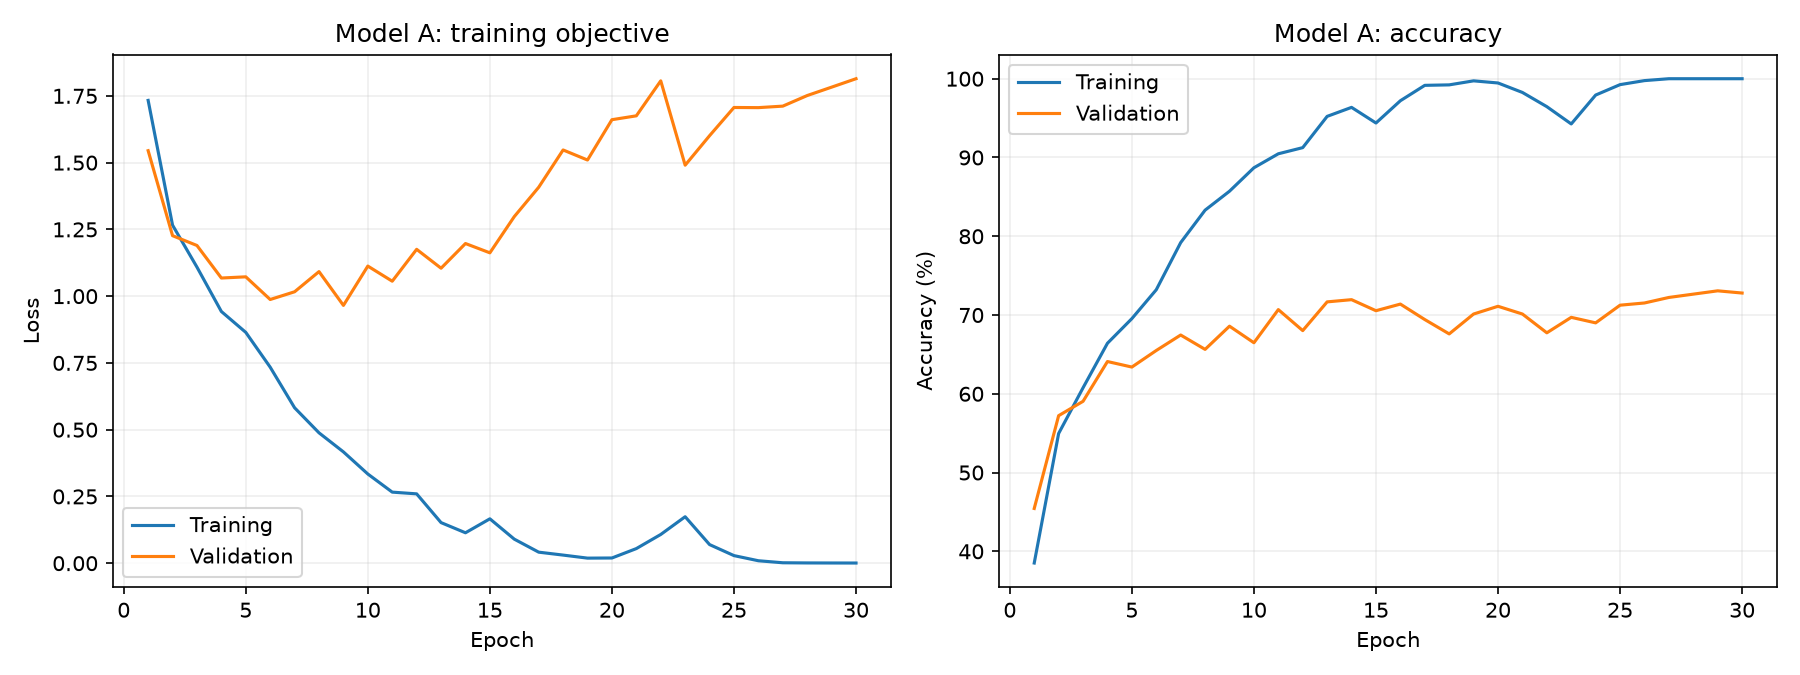

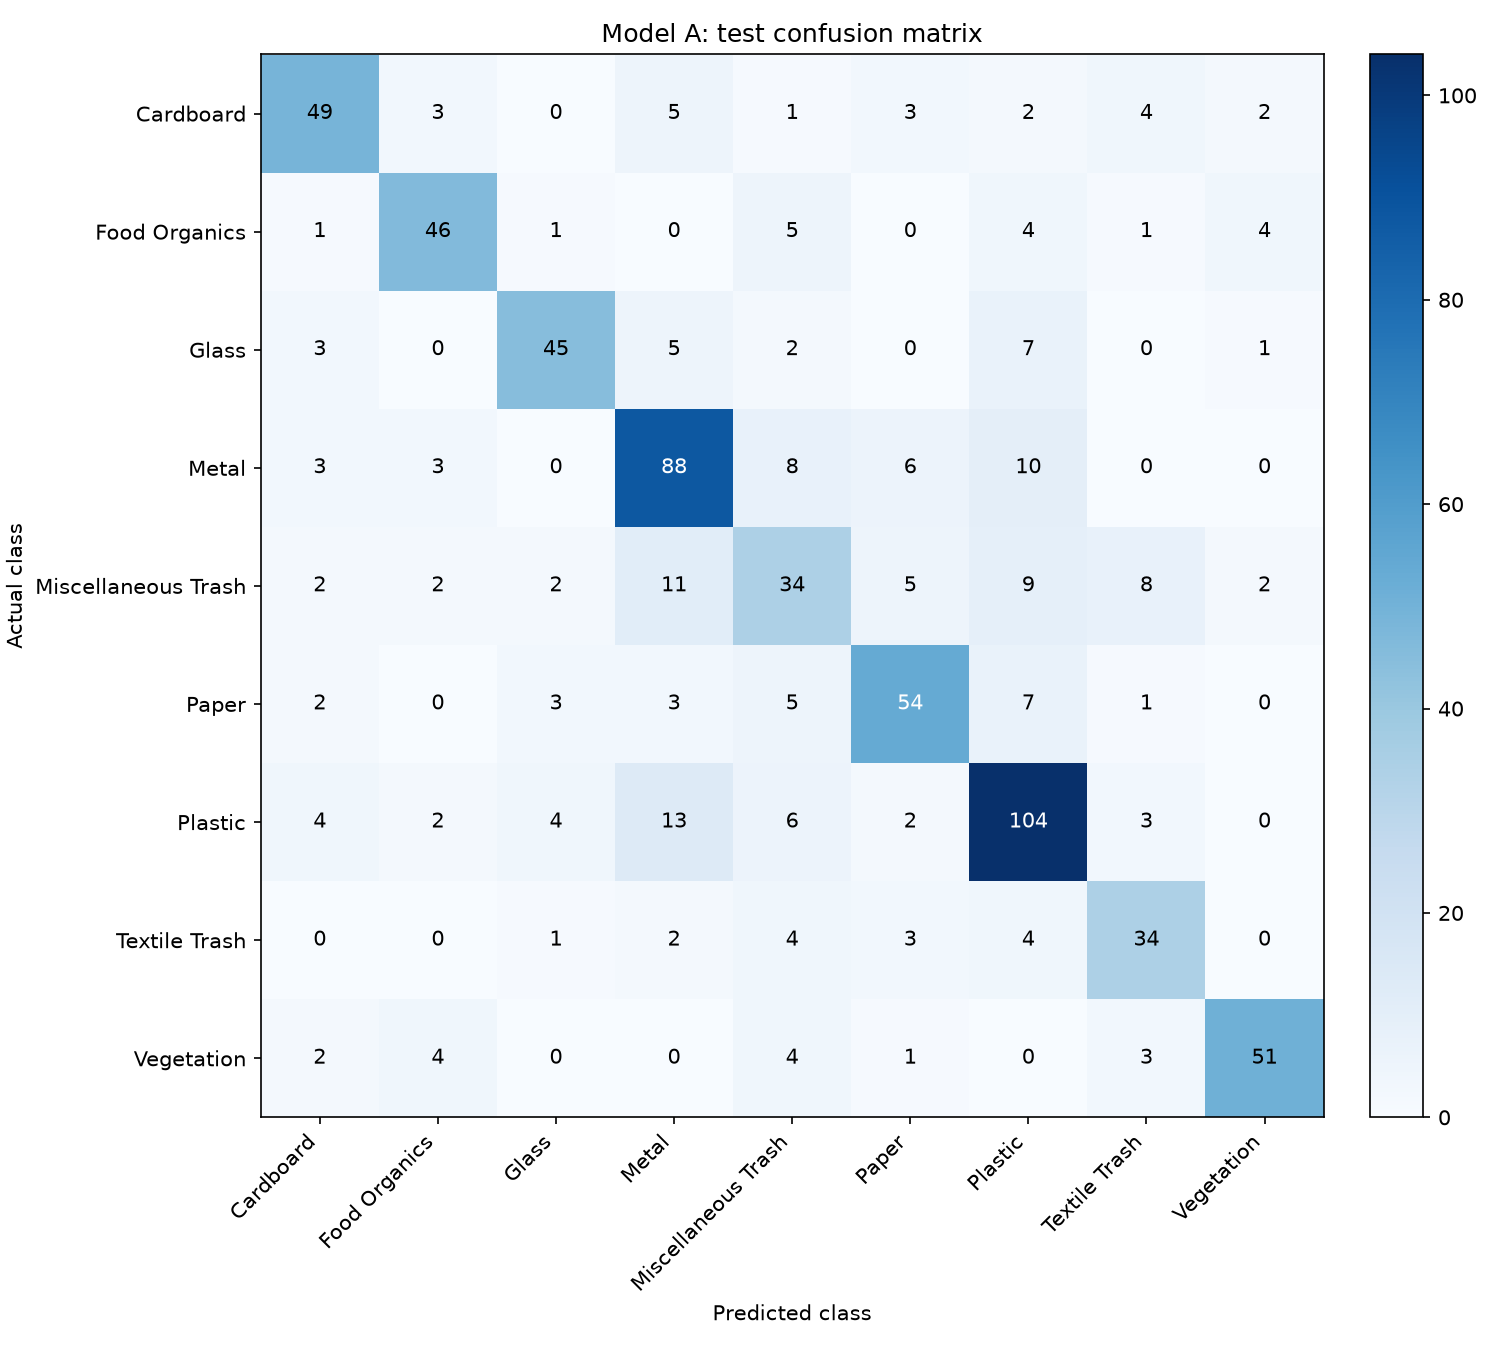

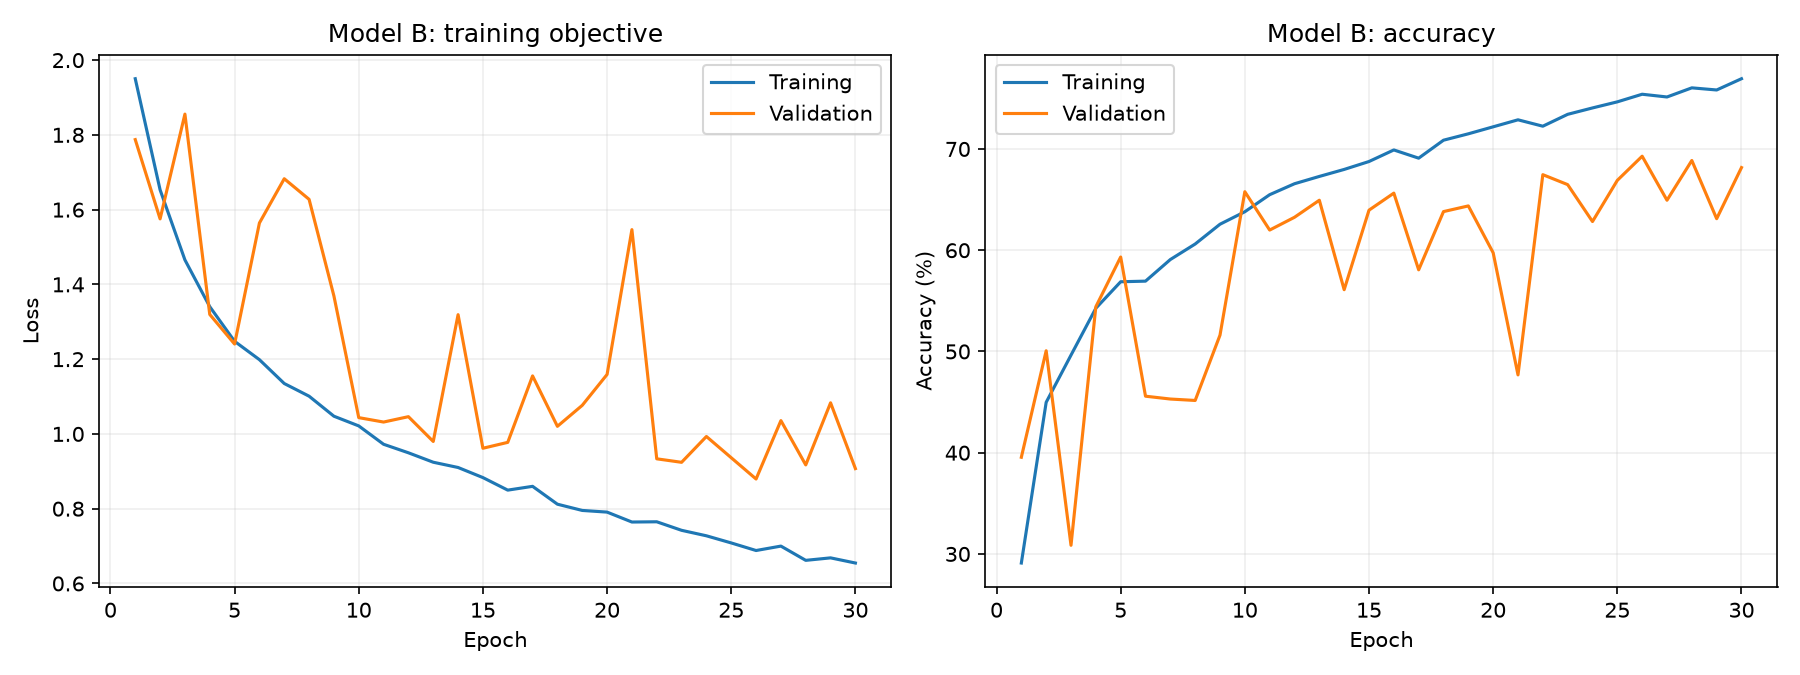

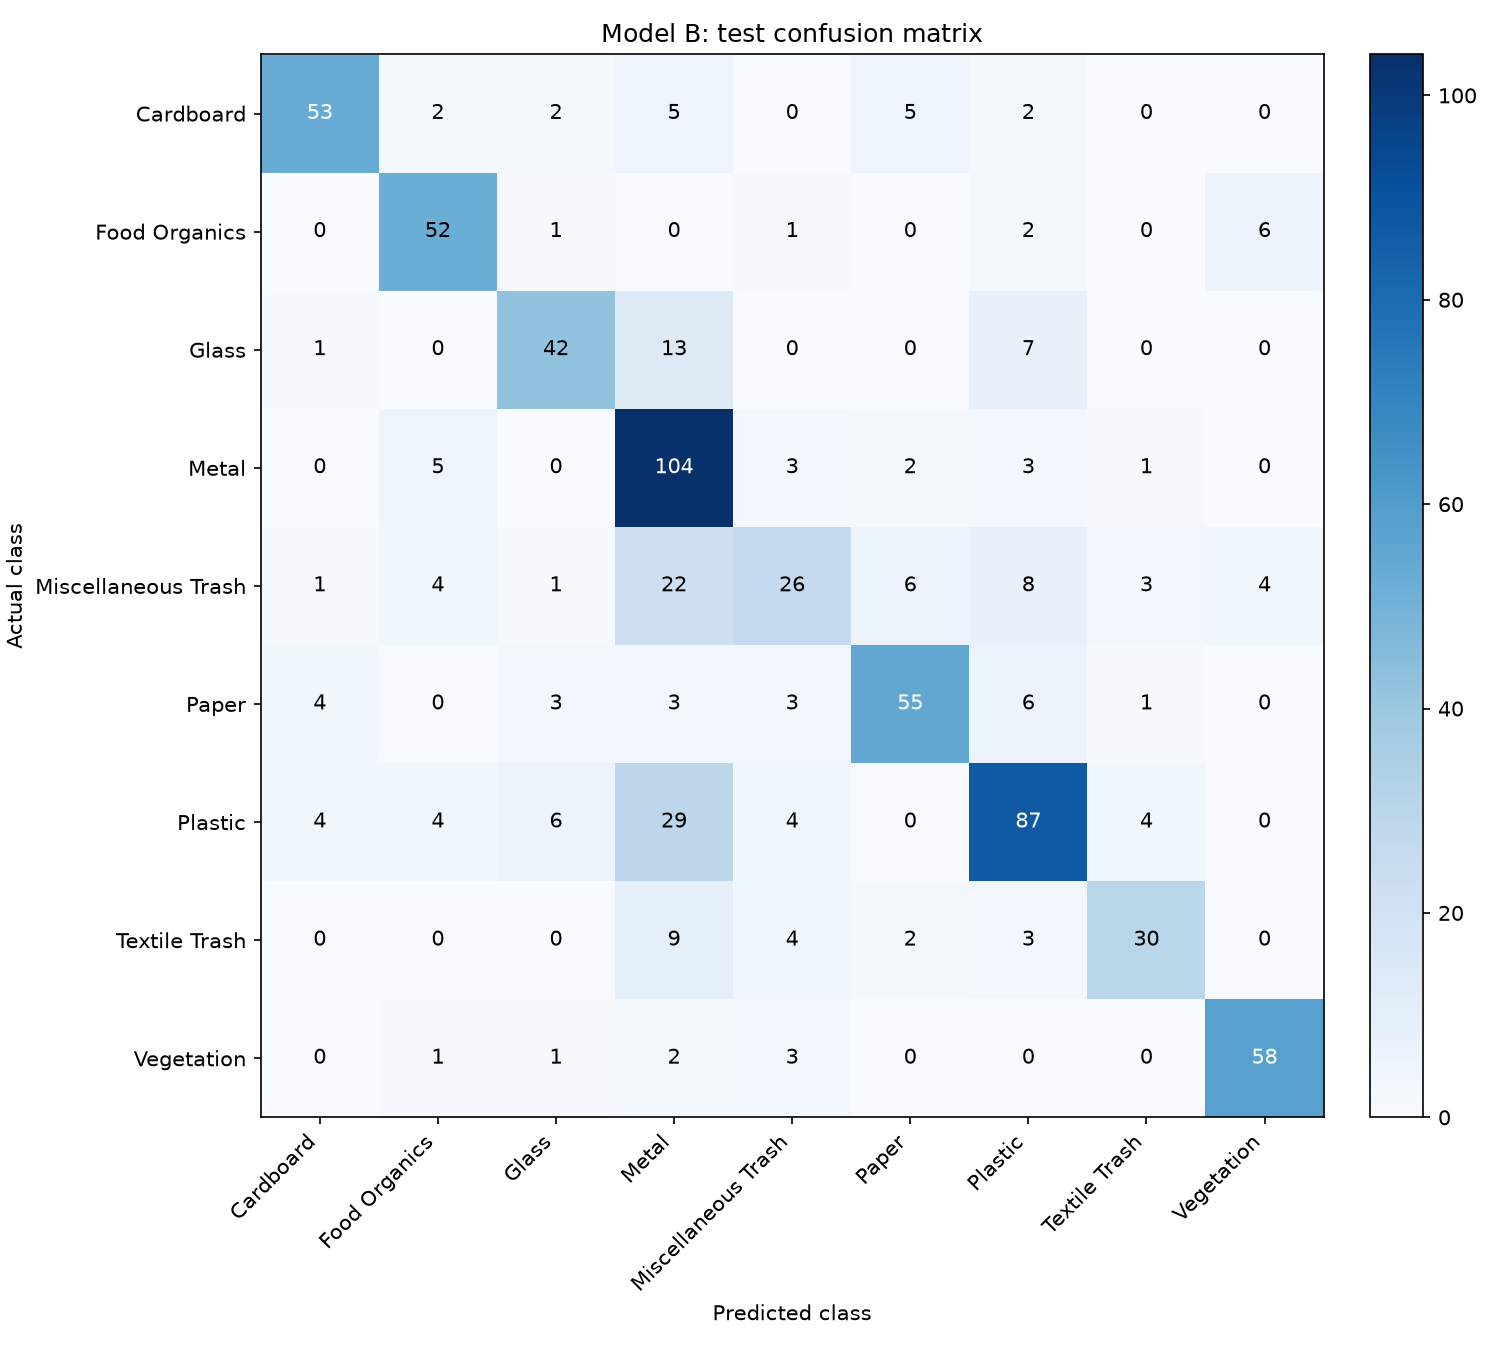

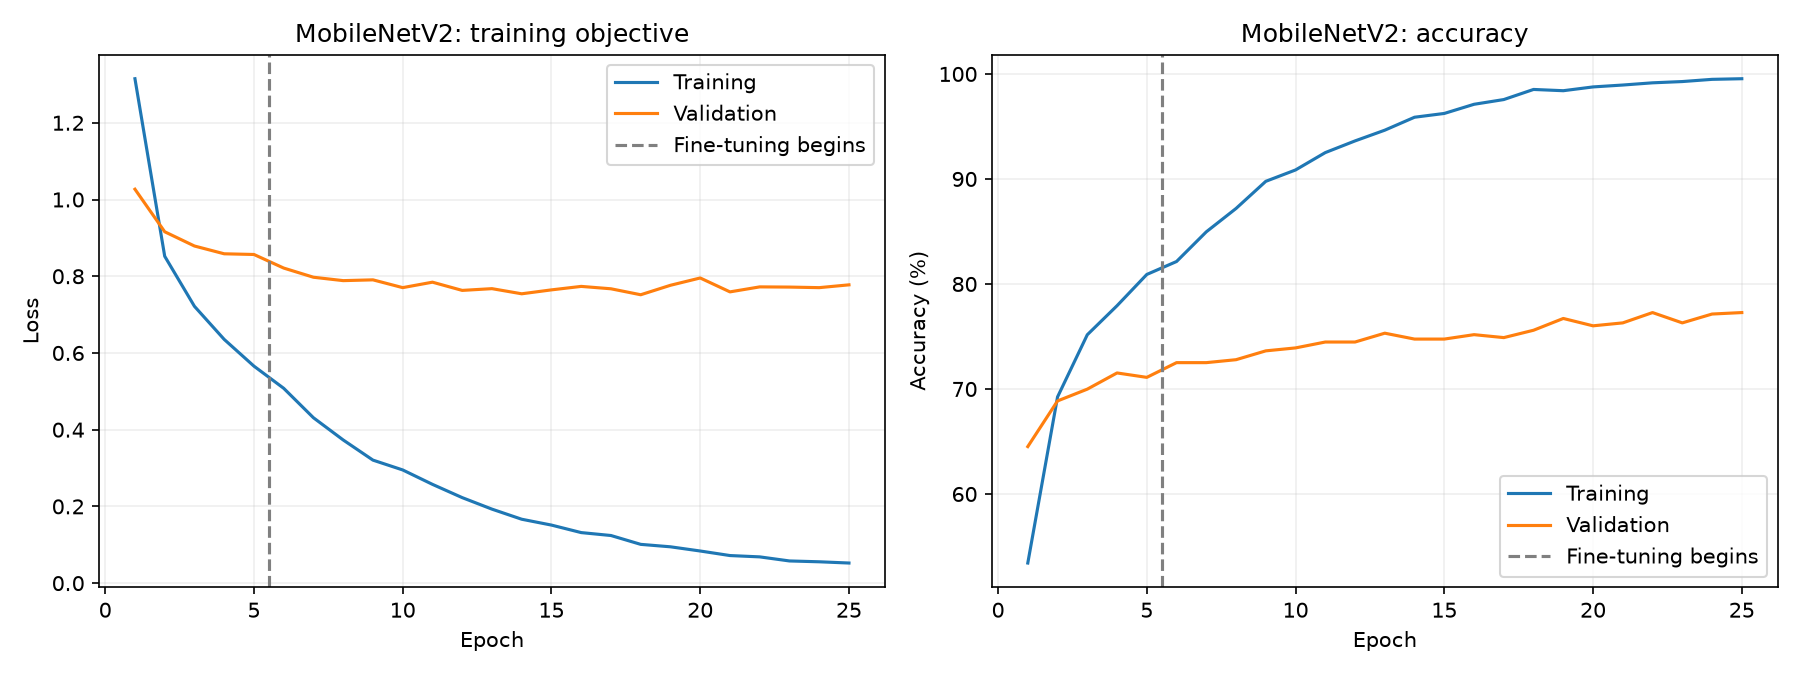

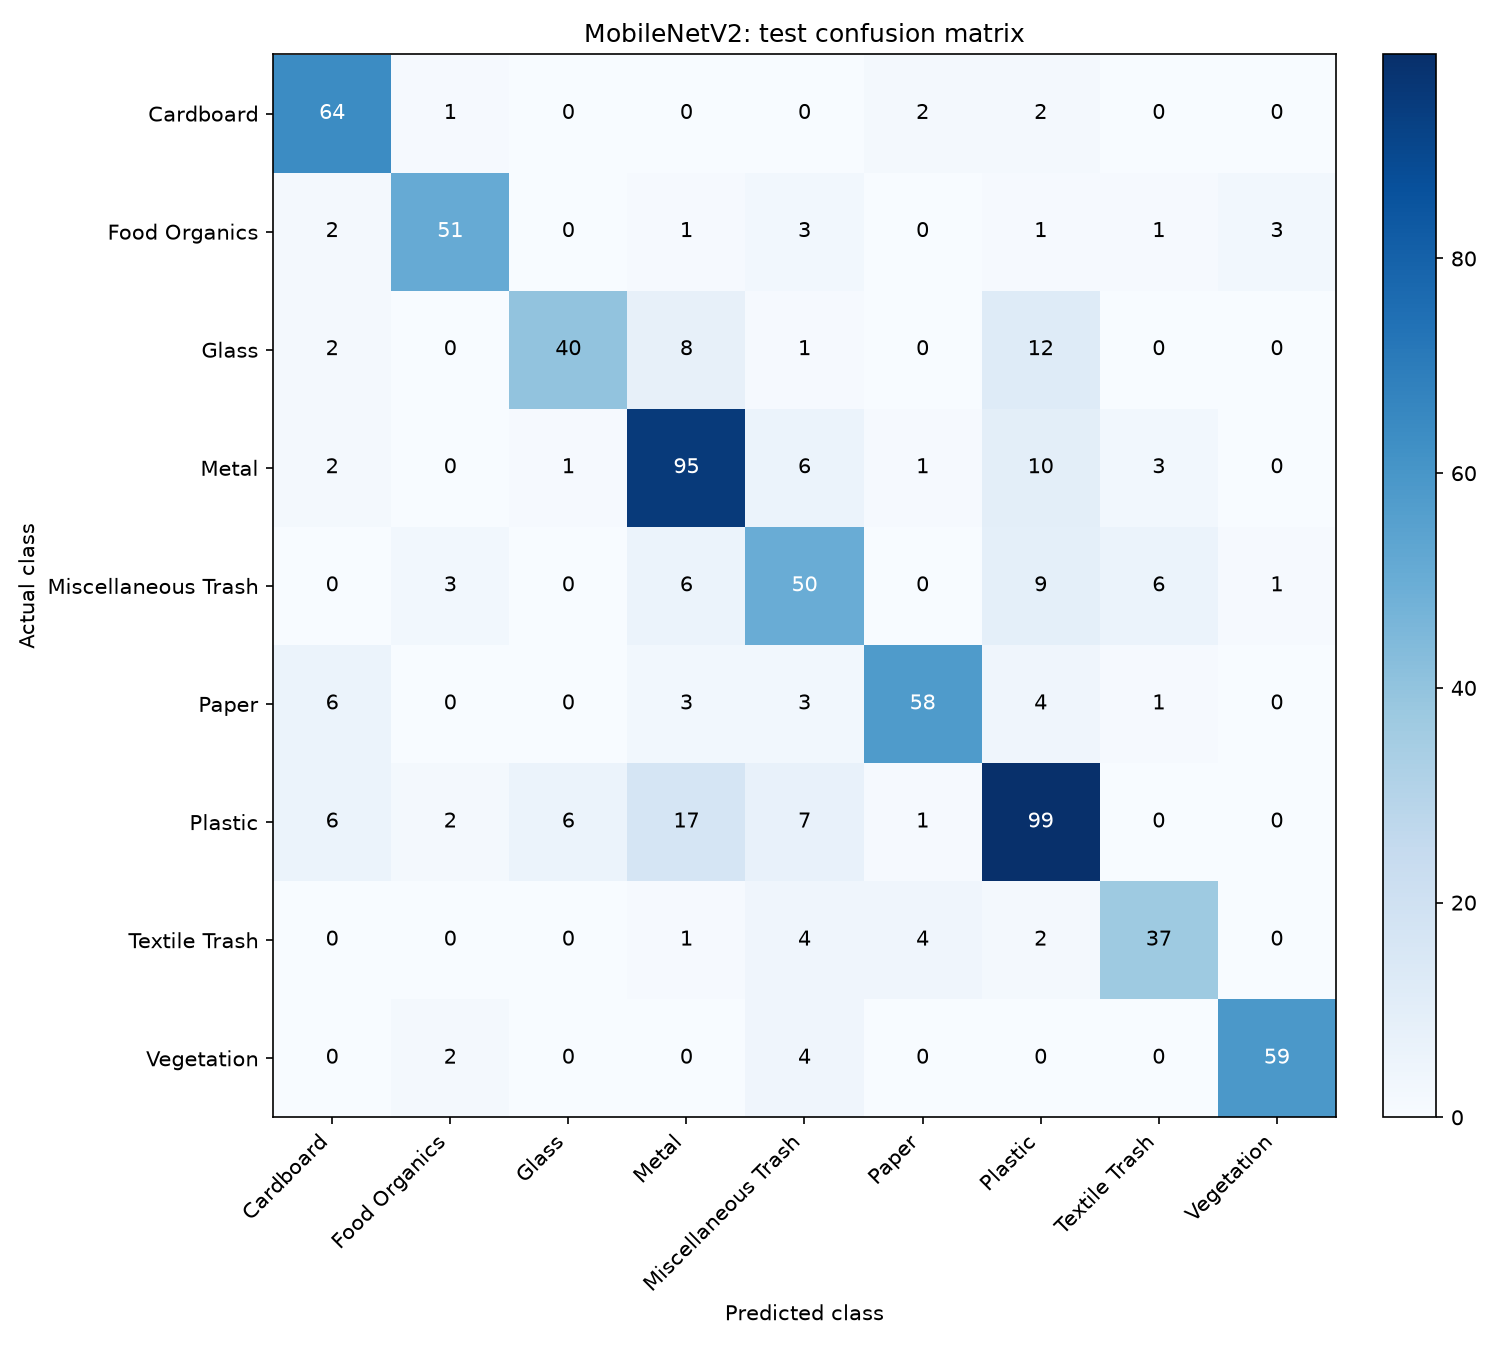

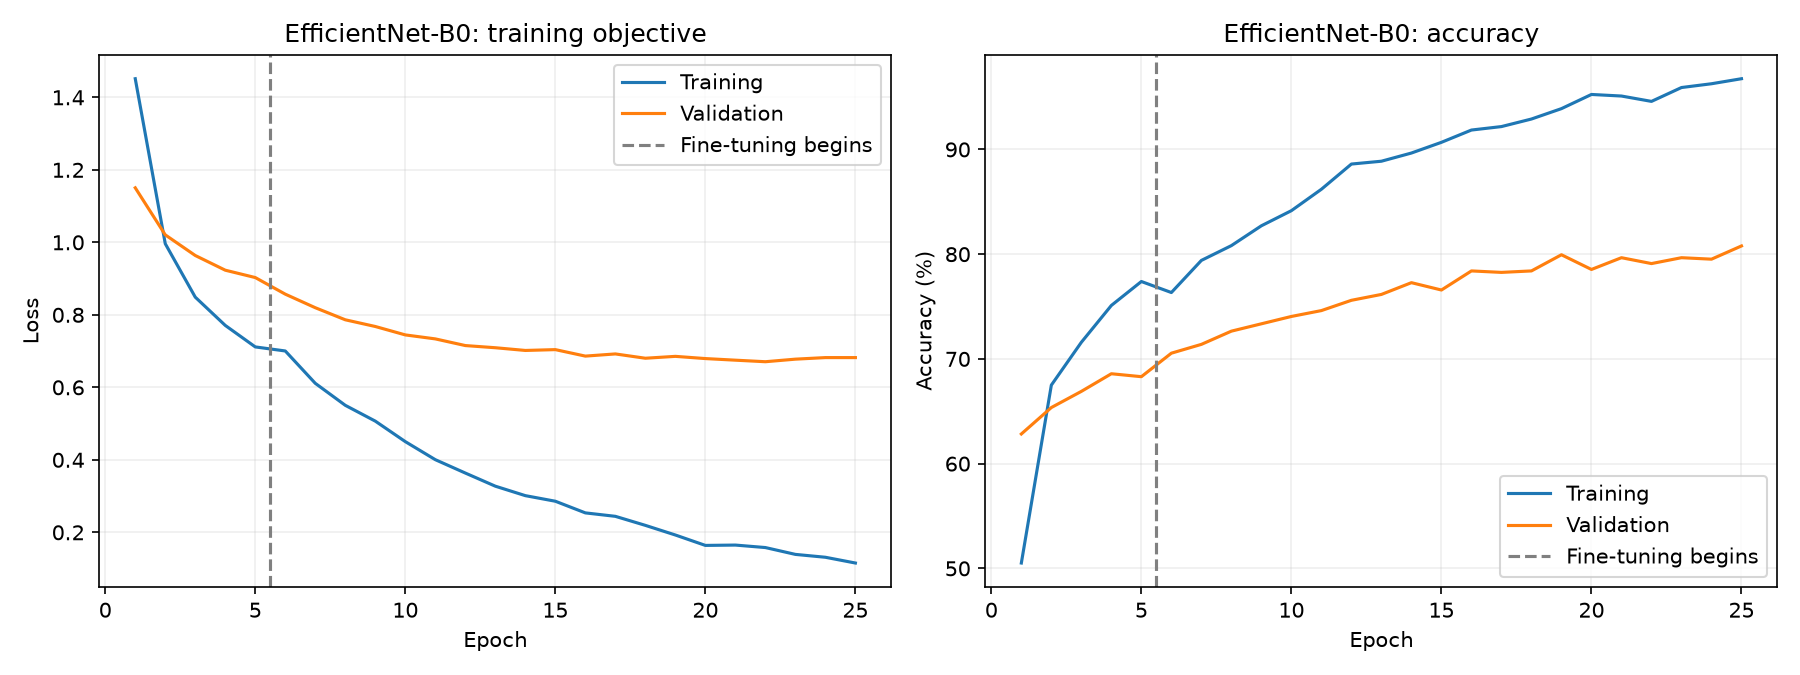

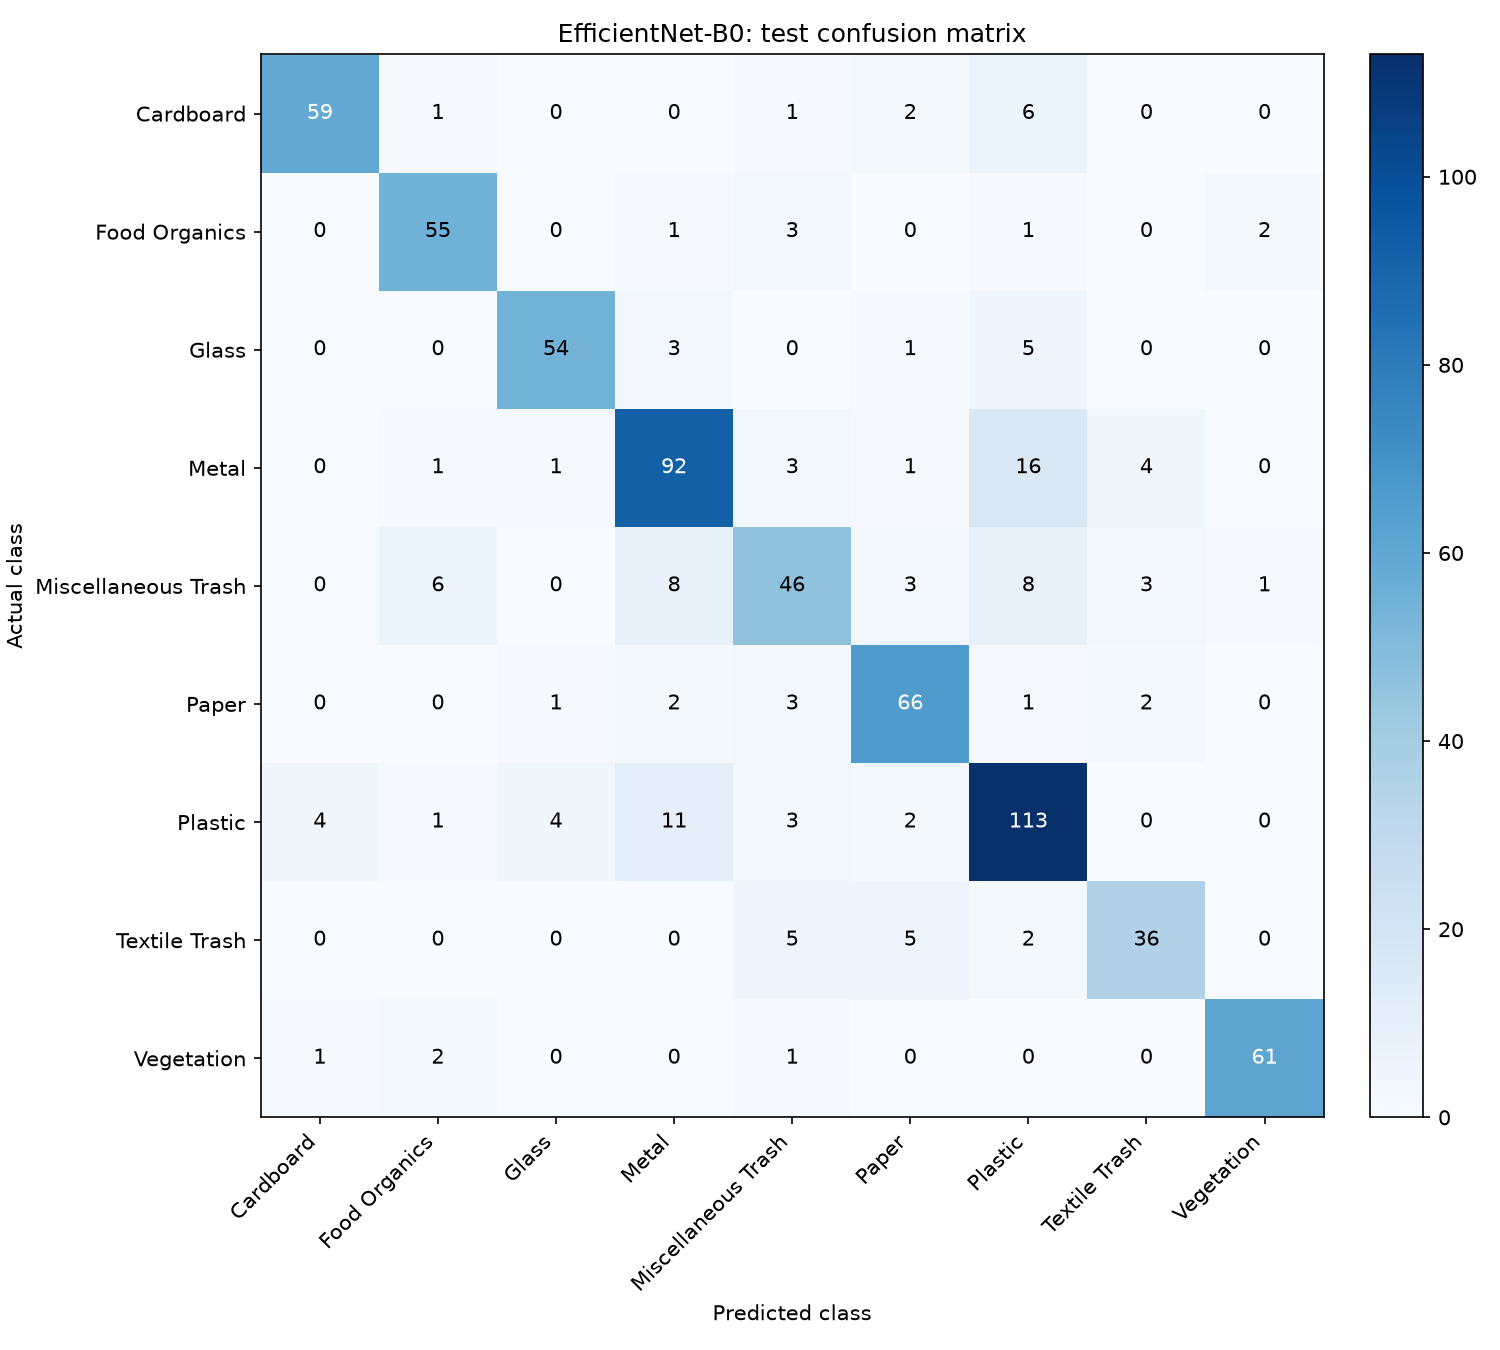

In [14]:
def show_saved_image(path):
    path = Path(path)
    if path.exists():
        display(DisplayImage(filename=str(path)))
    else:
        for base in REPOSITORY_RAW_BASES:
            try:
                with urllib.request.urlopen(base + path.as_posix(), timeout=15) as response:
                    data = response.read()
                display(DisplayImage(data=data))
                return
            except (urllib.error.HTTPError, urllib.error.URLError):
                continue
        raise FileNotFoundError(f'Plot unavailable: {path}. Download the repository assets or run training.')

plot_dir = OUTPUT_DIR if RUN_TRAINING else RECORDED_DIR
for name in final_results['models']:
    print(name)
    slug = name.lower().replace(' ', '_').replace('-', '_')
    show_saved_image(plot_dir / f'{slug}_curves.png')
    show_saved_image(plot_dir / f'{slug}_confusion.png')


## Optimizer comparison

The recorded study compares Adam, SGD and SGD with momentum 0.9 on Model B. Each candidate receives 30 epochs with identical starting weights and sample orders. Validation selects Adam at 0.001. Momentum retains past gradients in an update buffer; its effect depends on learning rate. Test results are used after configuration selection.

,Optimizer,Learning rate,Momentum,Best validation accuracy (%),Best epoch,Validation loss
0,Adam,0.0010,NaN,69.2847,26,0.8794
1,Adam,0.0003,NaN,64.5161,30,0.9993
2,SGD,0.0100,0.0,54.8387,25,1.3524
3,SGD,0.1000,0.0,64.7966,22,0.9488
4,SGD + momentum,0.0100,0.9,67.1809,20,0.9560
5,SGD + momentum,0.1000,0.9,67.0407,27,1.0241


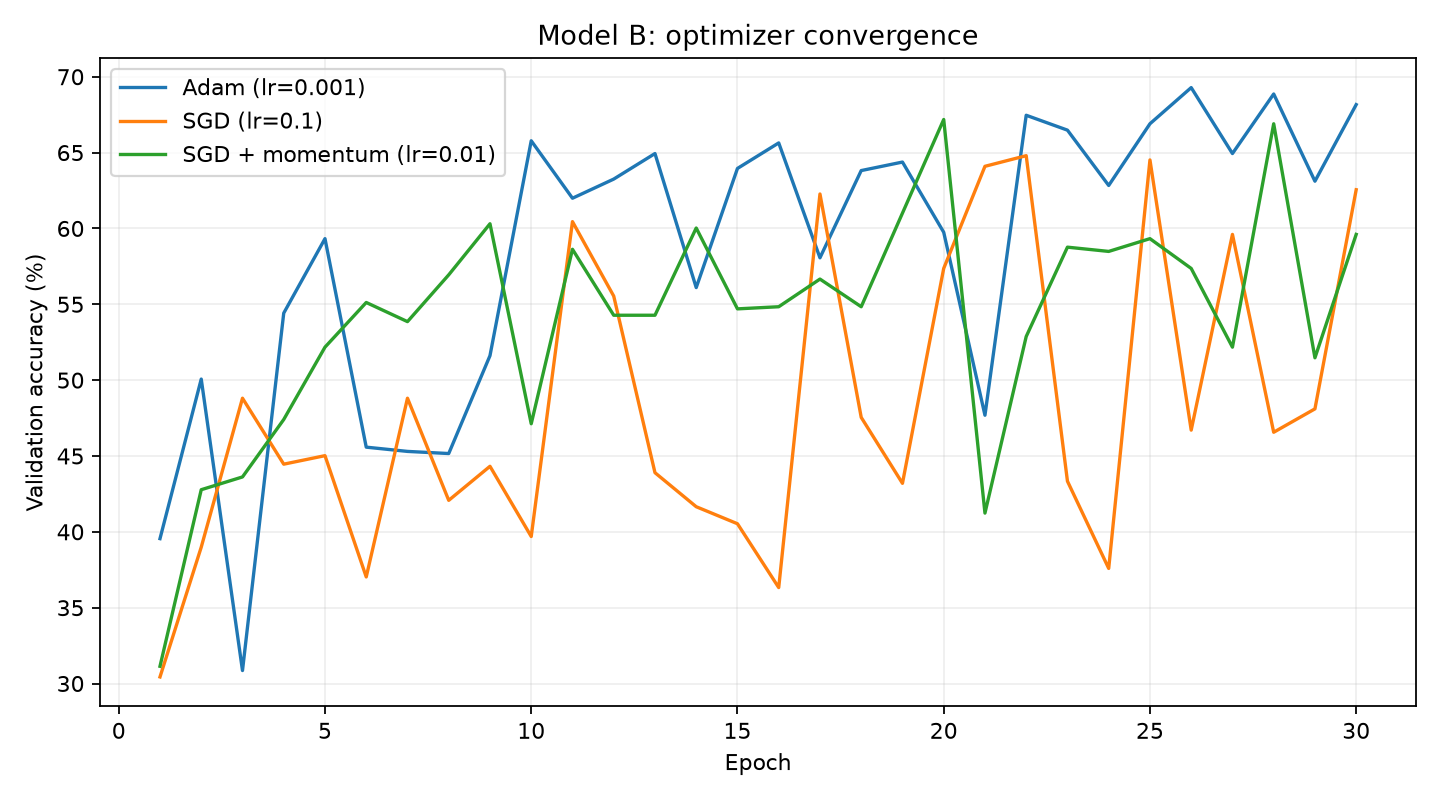

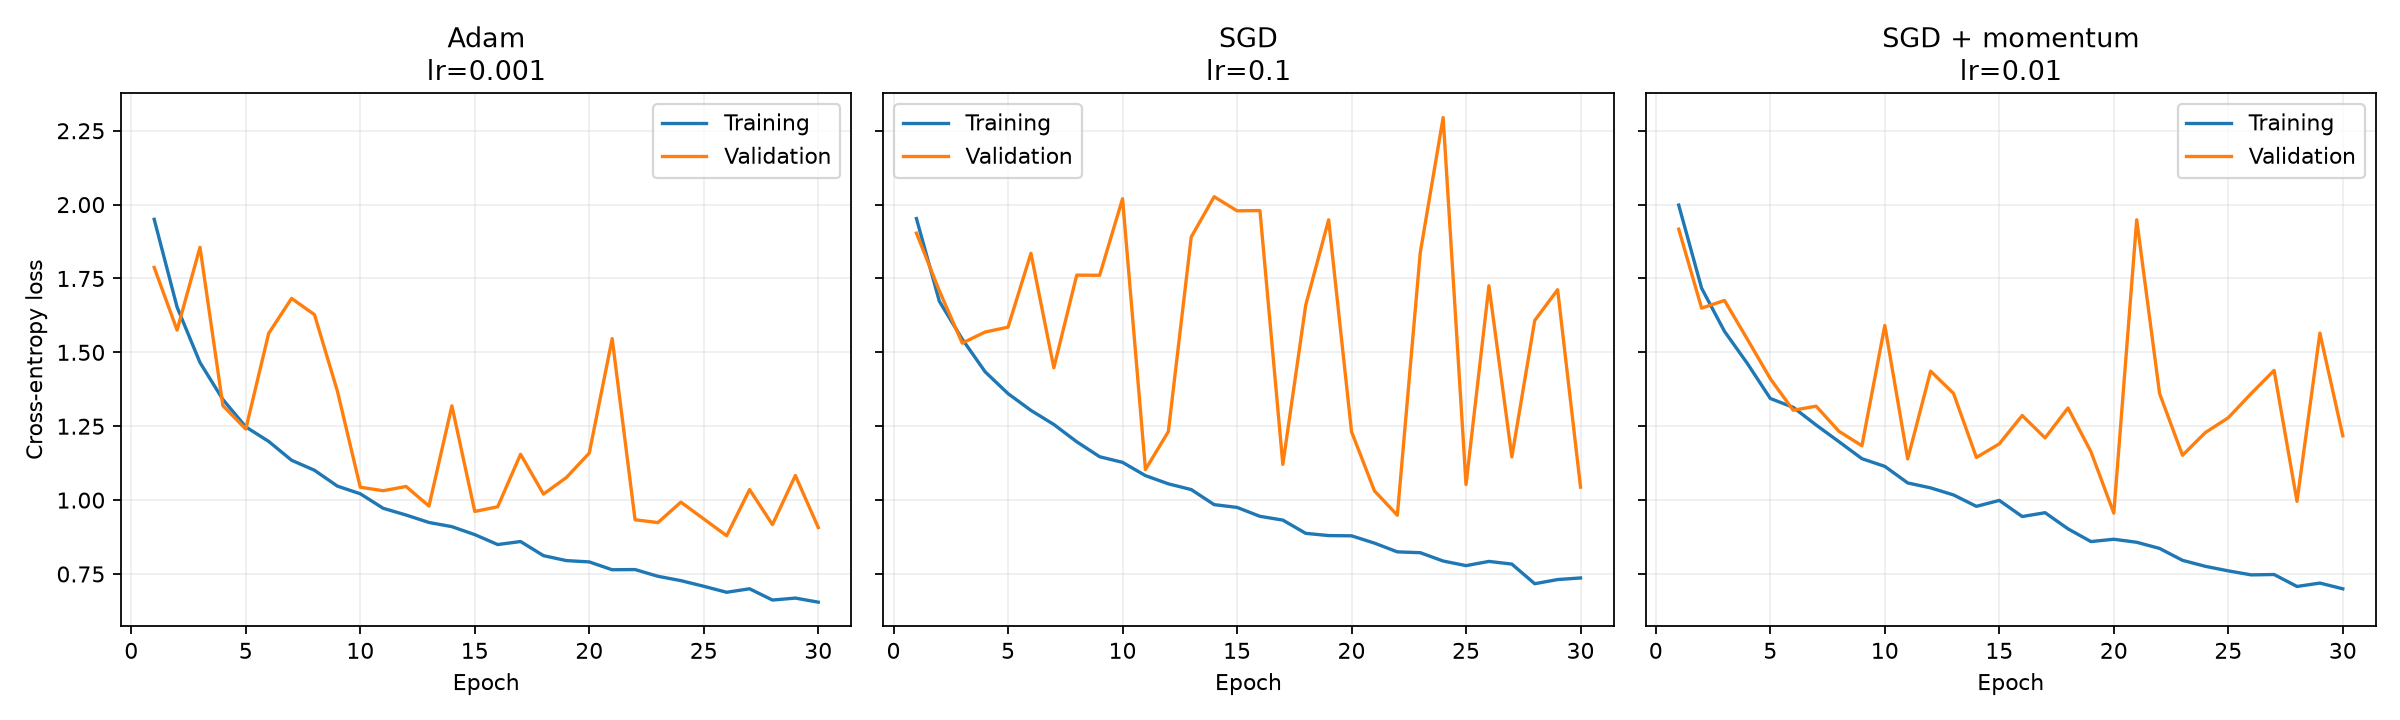

In [15]:
if RUN_OPTIMIZER_COMPARISON:
    optimizer_results, selected_model = compare_optimizers(
        lambda: LightWeightModel(len(image_data.classes)),
        split_data['train'], split_data['val'], epochs=30, seed=42, batch_size=32,
    )
    optimizer_dir = OUTPUT_DIR / 'optimizer_comparison'
    optimizer_figures = save_optimizer_comparison(
        optimizer_results, selected_model, split_data['test'], image_data.classes,
        optimizer_dir, optimizer_dir / 'checkpoints',
    )
    display(optimizer_summary(optimizer_results))
else:
    optimizer_dir = Path('results/optimizer_comparison')
    display(pd.DataFrame(OPTIMIZER_ROWS).round(4))
show_saved_image(optimizer_dir / 'validation_accuracy.png')
show_saved_image(optimizer_dir / 'loss_curves.png')


## Files for the LaTeX report

Use `results/final/report_tables.tex` for the result and optimizer tables, and the PNG files in `results/final/` for curves and confusion matrices. Layer-by-layer parameter calculations and activation justification are in `results/architecture/architecture_summary.md`. Full histories, split indices, model verification and source provenance are in `results/final/experiment.json`. Dataset and model citation entries are in `results/final/references.bib`. Previous tuning experiments remain separate from the final comparison.

The GitHub repository is https://github.com/AyubUmair/Pattern-Recognition. All final model results use RealWaste; the friend's digits notebook is retained separately.